In [ ]:
#libraries
import os
import numpy as np
import pandas as pd
import mesa_reader as mr
import pygyre as pg
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm,ListedColormap, BoundaryNorm, Normalize
from matplotlib.patches import Patch
from cycler import cycler
from scipy.signal import find_peaks
from scipy.integrate import trapezoid
from scipy.optimize import curve_fit

In [ ]:
# Thesis colour palette
my_colors = ['#5479B8', '#E95659',   '#E9B72F',  '#DD78A5',  '#8F78C6']
plt.rcParams['axes.prop_cycle'] = cycler(color=my_colors) # Default colour cycle for plots

s = ['#5479B8', '#8F78C6', '#DD78A5', '#E95659', '#E9B72F']
thesis_cmap = LinearSegmentedColormap.from_list('thesis_s', s, N=256) #Create a continuous colormap from the selected colors
thesis_cmap_r = thesis_cmap.reversed() #reversed version

In [ ]:
#reading history data
h = mr.MesaData('./../mesa_projects/new_sdb/LOGS/history.data')
for name in h.bulk_names:  #Print the names of all the columns
    print(name)

model_number
num_zones
star_age
log_dt
star_mass
log_abs_mdot
mass_conv_core
mix_type_1
mix_qtop_1
mix_type_2
mix_qtop_2
mix_type_3
mix_qtop_3
mix_type_4
mix_qtop_4
mix_type_5
mix_qtop_5
mix_type_6
mix_qtop_6
mix_type_7
mix_qtop_7
mix_type_8
mix_qtop_8
mix_type_9
mix_qtop_9
mix_type_10
mix_qtop_10
mix_type_11
mix_qtop_11
mix_type_12
mix_qtop_12
mix_type_13
mix_qtop_13
mix_type_14
mix_qtop_14
mix_type_15
mix_qtop_15
mix_type_16
mix_qtop_16
mix_type_17
mix_qtop_17
mix_type_18
mix_qtop_18
mix_type_19
mix_qtop_19
mix_type_20
mix_qtop_20
cz_top_omega
log_Lnuc
pp
cno
burn_type_1
burn_qtop_1
burn_type_2
burn_qtop_2
burn_type_3
burn_qtop_3
burn_type_4
burn_qtop_4
burn_type_5
burn_qtop_5
burn_type_6
burn_qtop_6
burn_type_7
burn_qtop_7
burn_type_8
burn_qtop_8
burn_type_9
burn_qtop_9
burn_type_10
burn_qtop_10
burn_type_11
burn_qtop_11
burn_type_12
burn_qtop_12
burn_type_13
burn_qtop_13
burn_type_14
burn_qtop_14
burn_type_15
burn_qtop_15
burn_type_16
burn_qtop_16
burn_type_17
burn_qtop_17
burn_typ

In [ ]:
model_to_age = dict(zip(h.model_number, h.star_age))#linking model number to star age

In [ ]:
# HR diagram
plt.plot(h.log_Teff,h.log_L,linewidth=2)
plt.xlabel(r"$\log_{10}(T_{eff}/K)$", fontsize=12)
plt.gca().invert_xaxis()
plt.ylabel(r"$\log_{10}(L/L_\odot)$", fontsize=12)
plt.gca().spines[:].set_linewidth(1.6)
plt.tick_params(width=1.5)
plt.savefig("CPM_os_HR.png")
plt.show()


: 

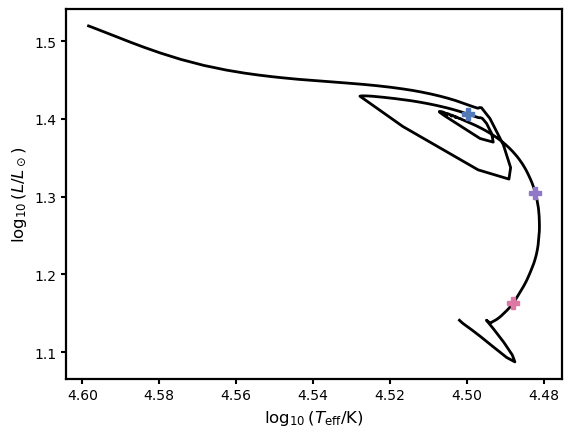

In [83]:
# HR diagram with stages
plt.plot(h.log_Teff,h.log_L,linewidth=2, c='black')
plt.xlabel(r"$\log_{10}(T_{eff}/K)$", fontsize=12)
plt.gca().invert_xaxis()
plt.ylabel(r"$\log_{10}(L/L_\odot)$", fontsize=12)
plt.plot(h.log_Teff[105],h.log_L[105],'P',  markersize=9, c=my_colors[3]) 
plt.plot(h.log_Teff[585],h.log_L[585],'P',markersize=9,c=my_colors[4]) 
plt.plot(h.log_Teff[900],h.log_L[900],'P', markersize=9, c=my_colors[0]) 
plt.gca().spines[:].set_linewidth(1.6)
plt.tick_params(width=1.5)
plt.savefig("CPM_os_HR.png")
plt.show()


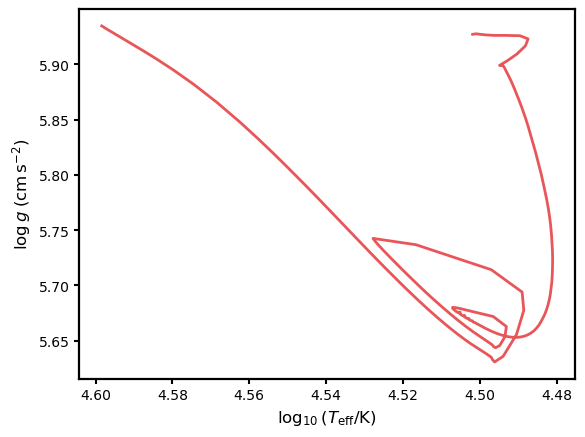

In [7]:
#Kiel diagram 
plt.plot(h.log_Teff,h.log_g,color='#E95659',linewidth=2)
plt.xlabel(r"$\log_{10}(T_{eff}/K)$", fontsize=12)
plt.gca().invert_xaxis()
plt.ylabel(r"$\log g\;(cm\,s^{-2})$", fontsize=12)
plt.gca().spines[:].set_linewidth(1.6)
plt.tick_params(width=1.5)
plt.savefig("CPM_os_kiel.png")
plt.show()

In [8]:
#reading profile data
files = os.listdir('./../mesa_projects/new_sdb/LOGS') #gives all the files in LOGs

profiles = []
for file in files:
    if file.startswith("profile") and file.endswith("data"):
        profiles.append(file)

# Trying to sort the list by number and not alphabetically, so we don't end up with profile 11 in the place of profile 2
def get_number(string_object): 
    number_part = string_object[7:] #because the word profile has 7 letters
    number_part = number_part.split('.')[0] #splits the number.data int 2 parts and only keeps the first
    return int(number_part)

profiles = sorted(profiles, key= get_number) #the key thing runs the elements through the function and then sorts


p = []
for name in profiles:
    prof = mr.MesaData('./../mesa_projects/new_sdb/LOGS/' + name)
    p.append(prof)
    
#so like p[0] is profile1 etc...


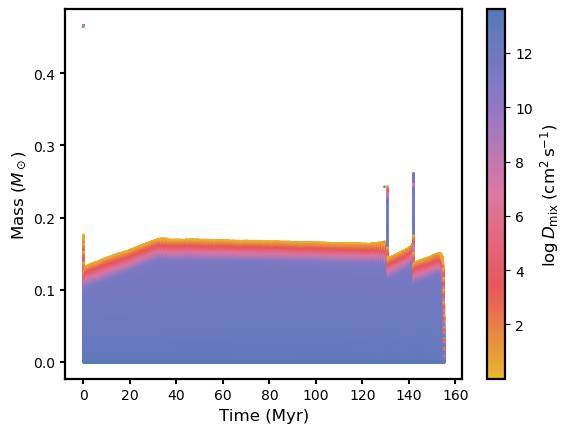

In [10]:
#Kipp with age
mixing_cmap = LinearSegmentedColormap.from_list('mixing_cmap', ['#E9B72F', '#E95659', '#DD78A5', '#8F78C6', '#5479B8'], N=256)


all_ages = []
all_mass = []
all_logD_mix = []

for prof in p: #get the age, mass coordinate and mixing coefficient from each profile
    model_number = prof.header_data['model_number']
    age = model_to_age[model_number]
    mass = prof.mass
    logD_mix = prof.log_D_mix
    only_conv = logD_mix >= 0  

    age_array = np.full(len(mass), age)

    all_ages.append(age_array[only_conv]) #Keep only regions with log(D_mix) >= 0
    all_mass.append(mass[only_conv]) #Keep only regions with log(D_mix) >= 0
    all_logD_mix.append(logD_mix[only_conv]) #Keep only regions with log(D_mix) >= 0

all_ages = np.concatenate(all_ages) #combine the data from all profiles into one array
all_mass = np.concatenate(all_mass) #combine the data from all profiles into one array
all_logD = np.concatenate(all_logD_mix) #combine the data from all profiles into one array

all_ages_myr = all_ages / 1e6 #stellar ages from years to Myr

ghasemi_plot = plt.scatter(all_ages_myr, all_mass, c=all_logD, cmap= mixing_cmap,s =0.5)

plt.xlabel('Time (Myr)', fontsize=12)
plt.ylabel(r'Mass ($M_\odot$)', fontsize=12)
plt.gca().spines[:].set_linewidth(1.6)
plt.tick_params(width=1.5)
cbar = plt.colorbar()
cbar.outline.set_linewidth(1.6)
cbar.set_label(r'$\log D_{mix}\;(cm^2\,s^{-1})$', fontsize=12)
plt.savefig("CPM_os_logDKipp.png")

plt.savefig("CPM_os_logFkipp.png")

plt.show()

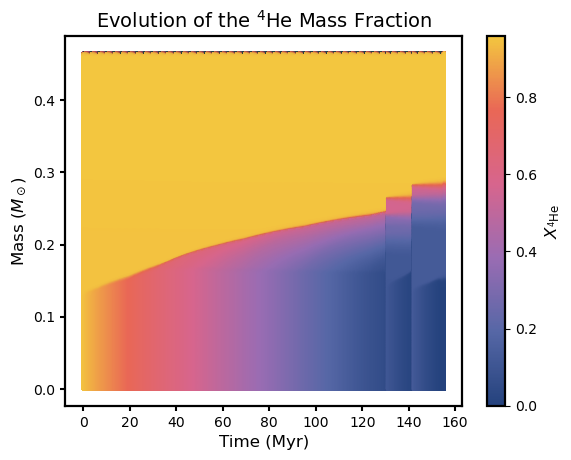

In [11]:
# Kipp with age using He4 abundance

he4_cmap = LinearSegmentedColormap.from_list('he4_cmap', [ '#24427D',  '#5667A6',  '#9A6CB3', '#D7658D','#E96756','#F3C63F', N=256)

all_ages = []
all_mass = []
all_he4 = []

for prof in p: #from each profile get the age, mass coordinate and helium-4 mass fraction
    model_number = prof.header_data['model_number']
    age = model_to_age[model_number]
    
    mass = prof.mass
    he4 = prof.he4   
    age_array = np.full(len(mass), age)

    all_ages.append(age_array)
    all_mass.append(mass)
    all_he4.append(he4)

all_ages = np.concatenate(all_ages)  #combine the data from all profiles into one array
all_mass = np.concatenate(all_mass)  #combine the data from all profiles into one array
all_he4 = np.concatenate(all_he4)  #combine the data from all profiles into one array

all_ages_myr = all_ages / 1e6 #stellar ages from years to Myr

plt.scatter(all_ages_myr, all_mass, c=all_he4, cmap=he4_cmap, s=2)
plt.title (r'Evolution of the $^4$He Mass Fraction', fontsize=14)
plt.xlabel('Time (Myr)', fontsize=12)
plt.ylabel(r'Mass ($M_\odot$)', fontsize=12)
plt.gca().spines[:].set_linewidth(1.6)
plt.tick_params(width=1.5)

cbar = plt.colorbar()
cbar.outline.set_linewidth(1.6)
cbar.set_label(r'$X_{^{4}He}$', fontsize=12)

plt.savefig("CPM_os_Hekipp.png")

plt.show()

In [12]:
#find age from profile number
model_number = p[584].header_data['model_number']
age = model_to_age[model_number]
print(age/ 1e6, "Myr")

86.02728449708381 Myr


In [13]:
MIX_NAMES = {
    -1: "crystallized",
    0: "no_mixing",
    1: "convective",
    2: "overshoot",
    3: "semiconvective",
    4: "thermohaline",
    5: "rotation",
    6: "rayleigh_taylor",
    7: "minimum_mixing",
    8: "anonymous",
    9: "leftover_convective",
    10: "phase_separation"
}

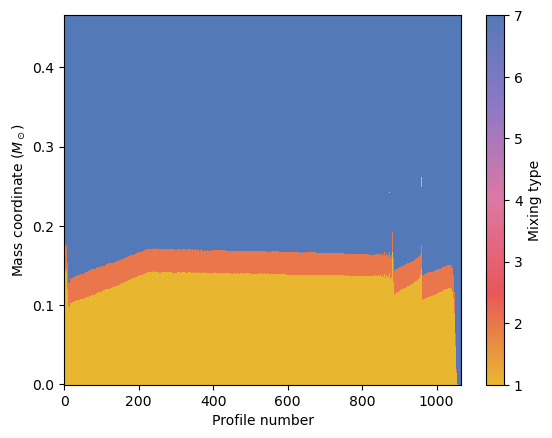

In [14]:
#Kipp with mixing types
mix_types = []


for prof in p: #get the mass coordinates and mixing types from each profile
    mass = prof.mass
    mix = prof.mixing_type
    
    y_grid = np.linspace(mass.min(), mass.max(), 500) #evenly spaced points on mass axis
    closest_mix = np.zeros_like(y_grid)
    
    for i, target_mass in enumerate(y_grid): # for every point of the grid find the closest mass in the profile
        j = np.argmin(np.abs(mass - target_mass))
        closest_mix[i] = mix[j] #and get the mixing type there
    
    mix_types.append(closest_mix)

# Combine the mixing types into a 2D array
mix_types = np.array(mix_types)
x = np.arange(len(mix_types))   
y = y_grid                      

plt.pcolormesh(x, y, mix_types.T, shading='nearest', cmap=thesis_cmap_r)

plt.xlabel("Profile number")
plt.ylabel(r"Mass coordinate ($M_\odot$)")

plt.colorbar(label="Mixing type")

plt.show()

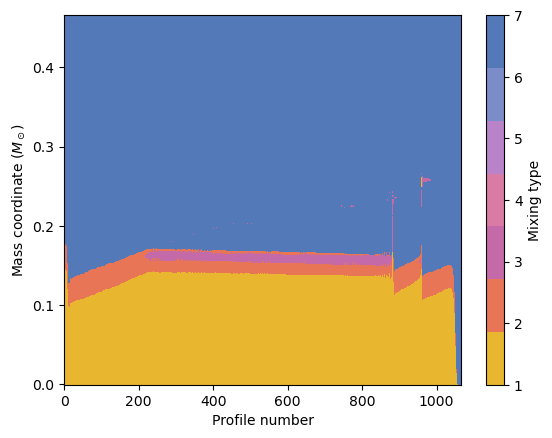

In [15]:
#plotting Kato semiconvective region 
from matplotlib.colors import ListedColormap

mixing_cmap = ListedColormap(['#E9B72F', '#E87555', '#C46AA8', '#D97BA5','#B883C8','#7B8DC8', '#5479B8'])

mix_types = []

for prof in p: #for every profile
    mass = prof.mass #mass coordinate of profile from MESA
    mix = prof.mixing_type.copy() #mixing type of profile from MESA
    semi = (prof.gradr_sub_grada > 0) & (prof.gradL_sub_gradr > 0) #defining what we consider semiconvecion, unstable by Schwarzschild and stable by Ledoux 
    mix[semi] = 3 #setting the mixing type to 3 for semiconvecive regions
    
    y_grid = np.linspace(mass.min(), mass.max(), 500) #evenly spaced points on mass axis
    closest_mix = np.zeros_like(y_grid) #zeros of the same dimension for the mixing array
    
    for i, target_mass in enumerate(y_grid): # for every point of the grid find the closest mass in the profile
        j = np.argmin(np.abs(mass - target_mass))
        closest_mix[i] = mix[j] #and get the mixing type there
    
    mix_types.append(closest_mix)

mix_types = np.array(mix_types)
x = np.arange(len(mix_types))  
y = y_grid                      

plt.pcolormesh(x, y, mix_types.T, shading='nearest',cmap=mixing_cmap,vmin=1, vmax=7)

plt.xlabel("Profile number")
plt.ylabel(r"Mass coordinate ($M_\odot$)")

cbar = plt.colorbar(ticks=np.arange(1, 8))
cbar.set_label("Mixing type")

plt.show()

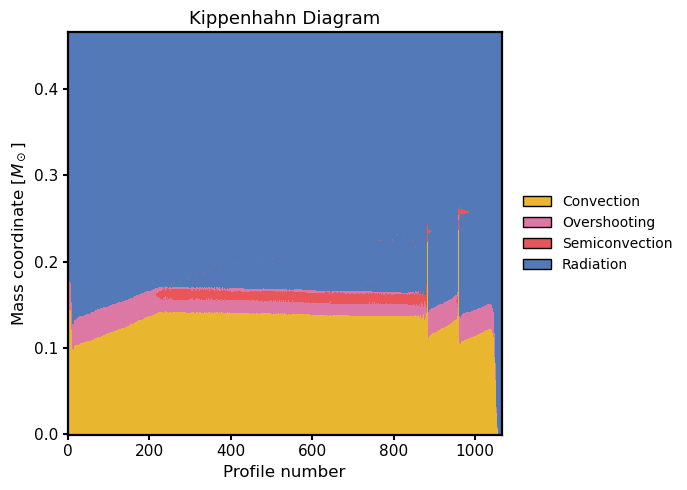

In [16]:
# plotting Kato semiconvective region

mixing_cmap = ListedColormap([
    '#E9B72F',  # 1 = convection
    '#DD78A5',  # 2 = overshooting
    '#E95659',  # 3 = semiconvection
    '#8F78C6',  # 4
    '#C6A7E2',  # 5
    '#8FA9D6',  # 6
    '#5479B8',  # 7 = radiative
])

mix_types = []

for prof in p:
    mass = prof.mass
    mix = prof.mixing_type.copy()

    #Kato semiconvection: unstable by Schwarzschild, stable by Ledoux
    semi = (prof.gradr_sub_grada > 0) & (prof.gradL_sub_gradr > 0)
    mix[semi] = 3

    y_grid = np.linspace(mass.min(), mass.max(), 500) #Create an evenly spaced mass grid with 500 points
    closest_mix = np.zeros_like(y_grid)

    for i, target_mass in enumerate(y_grid): #give each grid point the mixing type of the nearest mass coordinate
        j = np.argmin(np.abs(mass - target_mass))
        closest_mix[i] = mix[j]

    mix_types.append(closest_mix)

mix_types = np.array(mix_types) #Combine the mixing types into a 2D array
x = np.arange(len(mix_types))
y = y_grid

fig, ax = plt.subplots(figsize=(7, 5))

bounds = np.arange(0.5, 8, 1) #discrete colour boundaries for each mixing type
norm = BoundaryNorm(bounds, mixing_cmap.N)

pcm = ax.pcolormesh(x, y, mix_types.T, shading='nearest', cmap=mixing_cmap, norm=norm)
ax.set_xlabel("Profile number", fontsize=12)
ax.set_ylabel(r"Mass coordinate [$M_\odot$]", fontsize=12)
ax.set_title("Kippenhahn Diagram", fontsize=13)

ax.spines[:].set_linewidth(1.6)
ax.tick_params(width=1.5, labelsize=11)

#legend
legend_elements = [
    Patch(facecolor='#E9B72F', edgecolor='black', label='Convection'),
    Patch(facecolor='#DD78A5', edgecolor='black', label='Overshooting'),
    Patch(facecolor='#E95659', edgecolor='black', label='Semiconvection'),
    Patch(facecolor='#5479B8', edgecolor='black', label='Radiation'),
]
ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)

plt.tight_layout()
plt.savefig("CPM_os_mixtype1.png")
plt.show()

In [177]:
#find age from profile number
model_number = p[850].header_data['model_number']
age = model_to_age[model_number]
print(age/ 1e6, "Myr")

125.92728449708382 Myr


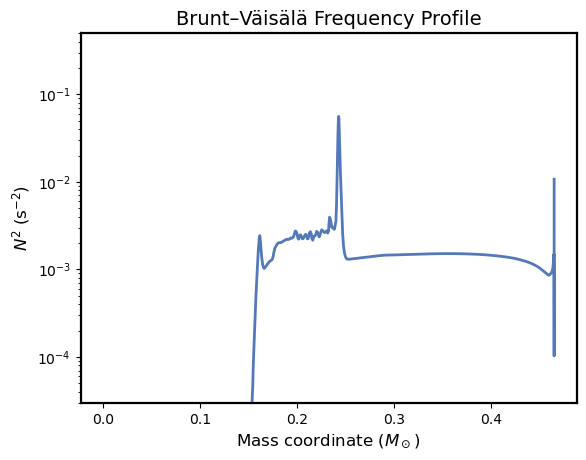

In [171]:
#Brunt Vaisala plot

i = 870 #Select the MESA profile

plt.plot(p[i].mass, p[i].brunt_N2, linewidth=2)
plt.yscale('log')
plt.title(r'Brunt–Väisälä Frequency Profile', fontsize=14)
plt.xlabel(r'Mass coordinate ($M_\odot$)', fontsize=12)
plt.ylabel(r'$N^2\;(s^{-2})$', fontsize=12)
plt.gca().spines[:].set_linewidth(1.6)

plt.ylim(3e-5,0.5)
plt.show()

In [46]:
p[i].bulk_names # profile data columns

('zone',
 'mass',
 'logR',
 'logT',
 'logRho',
 'logP',
 'x_mass_fraction_H',
 'y_mass_fraction_He',
 'z_mass_fraction_metals',
 'dm',
 'radius',
 'rmid',
 'mu',
 'grada',
 'csound',
 'pp',
 'cno',
 'tri_alpha',
 'h1',
 'he4',
 'c12',
 'n14',
 'o16',
 'ne20',
 'na23',
 'mg24',
 'al27',
 'si28',
 's32',
 'ar40',
 'ca40',
 'cr52',
 'mn55',
 'fe56',
 'ni58',
 'opacity',
 'gradT',
 'gradr',
 'gradL',
 'ledoux_stable',
 'log_mlt_D_mix',
 'gradr_div_grada',
 'gradr_sub_grada',
 'gradL_sub_gradr',
 'mixing_type',
 'log_D_mix',
 'log_D_conv',
 'log_D_ovr',
 'log_D_minimum',
 'gradL_composition_term',
 'omega',
 'shear',
 'log_am_nu_non_rot',
 'log_am_nu_rot',
 'log_am_nu',
 'omega_div_omega_crit',
 'am_log_nu_omega',
 'am_log_D_DSI',
 'am_log_D_SH',
 'am_log_D_SSI',
 'am_log_D_ES',
 'am_log_D_GSF',
 'am_log_D_ST',
 'am_log_nu_ST',
 'diffusion_D_h1',
 'diffusion_D_he4',
 'diffusion_D_c12',
 'diffusion_D_n14',
 'diffusion_D_o16',
 'diffusion_D_ne20',
 'diffusion_D_na23',
 'diffusion_D_mg24',
 'd

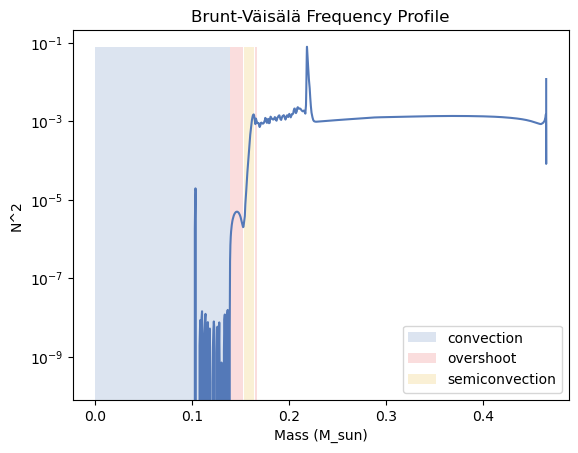

In [49]:
#brunt vaisala and mixing type
i = 585 #select the MESA profile

mass = p[i].mass
mix = p[i].mixing_type.copy()
semi = (p[i].gradr_sub_grada > 0) & (p[i].gradL_sub_gradr > 0) #find Kato-semiconvective regions
mix[semi] = 3

#define convection, overshooting and semiconvection regions from their mixing types
conv = (mix == 1)
os = (mix == 2)
semi = (mix == 3)

plt.plot(mass, p[i].brunt_N2)
plt.fill_between(mass,p[i].brunt_N2.min(), p[i].brunt_N2.max(),where = conv, alpha = 0.2, label = 'convection')
plt.fill_between(mass,p[i].brunt_N2.min(), p[i].brunt_N2.max(),where = os, alpha = 0.2, label = 'overshoot')
plt.fill_between(mass,p[i].brunt_N2.min(), p[i].brunt_N2.max(),where = semi, alpha = 0.2 , label = 'semiconvection')
plt.yscale('log')
plt.title('Brunt-Väisälä Frequency Profile')
plt.xlabel("Mass (M_sun)")
plt.ylabel("N^2")
plt.legend()
    
plt.show()

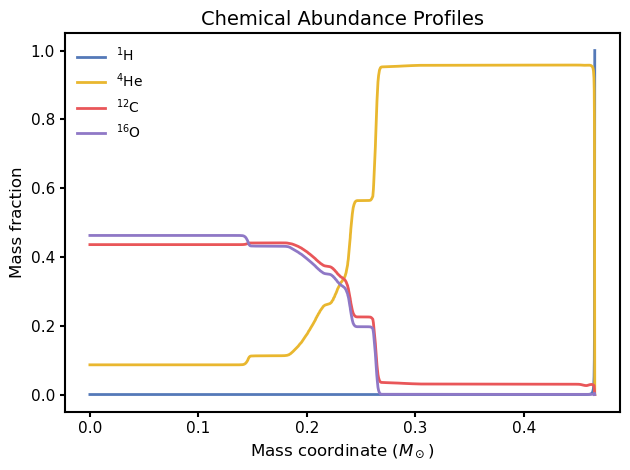

In [89]:
# Abundance profiles with mass

i = 900 #Select the MESA profile

plt.plot(p[i].mass, p[i].h1,  color=my_colors[0], linewidth=2, label=r'$^1$H')
plt.plot(p[i].mass, p[i].he4, color=my_colors[2], linewidth=2, label=r'$^4$He')
plt.plot(p[i].mass, p[i].c12, color=my_colors[1], linewidth=2, label=r'$^{12}$C')
plt.plot(p[i].mass, p[i].o16, color=my_colors[4], linewidth=2, label=r'$^{16}$O')

plt.title('Chemical Abundance Profiles', fontsize=14)
plt.xlabel(r'Mass coordinate ($M_\odot$)', fontsize=12)
plt.ylabel('Mass fraction', fontsize=12)
plt.legend(frameon=False)

plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)
# plt.axvline(0.154, color='black', linestyle='--')
# plt.axvline(0.262, color='black', linestyle='--')
# plt.axvline(0.254, color=my_colors[1], linestyle='--')
# plt.axvline(0.183, color=my_colors[0], linestyle='--')

plt.tight_layout()
plt.savefig("stage3_abundances.png")
plt.show()

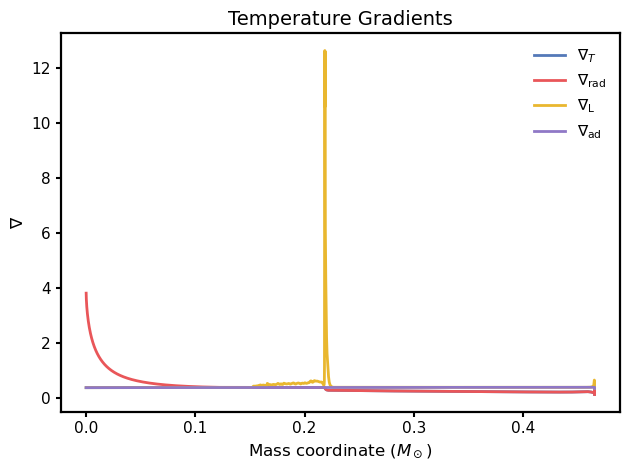

In [28]:
#Gradients with mass coord
#Plot the real, radiative, Ledoux and adiabatic temperature gradients as functions of the enclosed mass
plt.plot(p[i].mass, p[i].gradT, color=my_colors[0], linewidth=2, label=r'$\nabla_T$')
plt.plot(p[i].mass, p[i].gradr, color=my_colors[1], linewidth=2, label=r'$\nabla_{rad}$')
plt.plot(p[i].mass, p[i].gradL, color=my_colors[2], linewidth=2, label=r'$\nabla_{L}$')
plt.plot(p[i].mass, p[i].grada, color=my_colors[4], linewidth=2, label=r'$\nabla_{ad}$')

plt.title('Temperature Gradients', fontsize=14)
plt.xlabel(r'Mass coordinate ($M_\odot$)', fontsize=12)
plt.ylabel(r'$\nabla$', fontsize=12)

plt.legend(frameon=False, fontsize=11)
plt.gca().spines[:].set_linewidth(1.6)
plt.tick_params(width=1.5, labelsize=11)

plt.tight_layout()
plt.savefig("CPM_os_gradients.png")
plt.show()

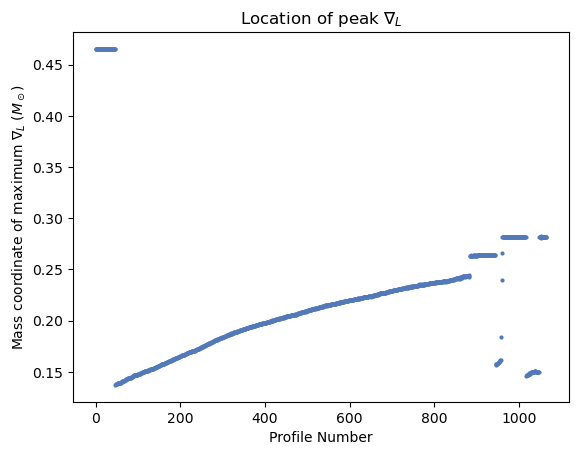

In [20]:
#the peak in gradL defines the semiconvection region boundary
peak_mass = []
for profile in p: #find the mass coordinate where the Ledoux gradient is largest in each profile
    idx = np.argmax(profile.gradL)
    peak_mass.append(profile.mass[idx])

peak_mass = np.array(peak_mass)

profile_number = np.arange(len(p))#create an array of profile indices

plt.scatter(profile_number, peak_mass, marker='o', s=4)

plt.xlabel('Profile Number')
plt.ylabel(r'Mass coordinate of maximum $\nabla_L$ ($M_\odot$)')
plt.title(r'Location of peak $\nabla_L$')

plt.show()

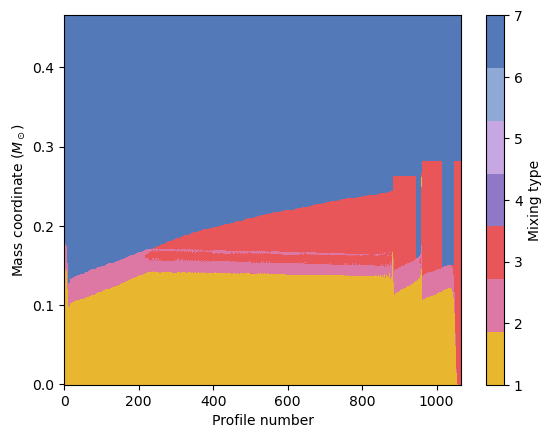

In [24]:
#plotting Kipp with mixing types with semiconvection border defined by the peak of grad L 

#range of profiles where the additional semiconvective region is identified
profile_start = 200
profile_end = 1200

mix_types = []

for prof_num, prof in enumerate(p):
    mass = prof.mass
    mix = prof.mixing_type.copy()
    semi = (prof.gradr_sub_grada > 0) & (prof.gradL_sub_gradr > 0)
    mix[semi] = 3

    # Add region below gradL peak as mixing_type 3 which is semiconvection
    if profile_start <= prof_num <= profile_end:
        peak_idx = np.argmax(prof.gradL)
        below_peak = np.arange(len(mix)) > peak_idx  #grid indices after the Ledoux gradient peak
        protected = (mix == 1) | (mix == 2)  # Preserve regions already classified as convection or overshooting
        mix[below_peak & ~protected] = 3 #Assign the remaining selected regions as semiconvection

    y_grid = np.linspace(mass.min(), mass.max(), 500)     #evenly spaced mass grid with 500 points
    closest_mix = np.zeros_like(y_grid)

    for i, target_mass in enumerate(y_grid): #assign at each grid point the mixing type of the nearest mass coordinate
        j = np.argmin(np.abs(mass - target_mass))
        closest_mix[i] = mix[j]

    mix_types.append(closest_mix)

mix_types = np.array(mix_types)#mixing types into a 2D array
x = np.arange(len(mix_types))
y = y_grid

plt.pcolormesh(x, y, mix_types.T, shading='nearest', cmap=mixing_cmap,vmin=1, vmax=7)

plt.xlabel("Profile number")
plt.ylabel(r"Mass coordinate ($M_\odot$)")
plt.colorbar(label="Mixing type")

plt.show()

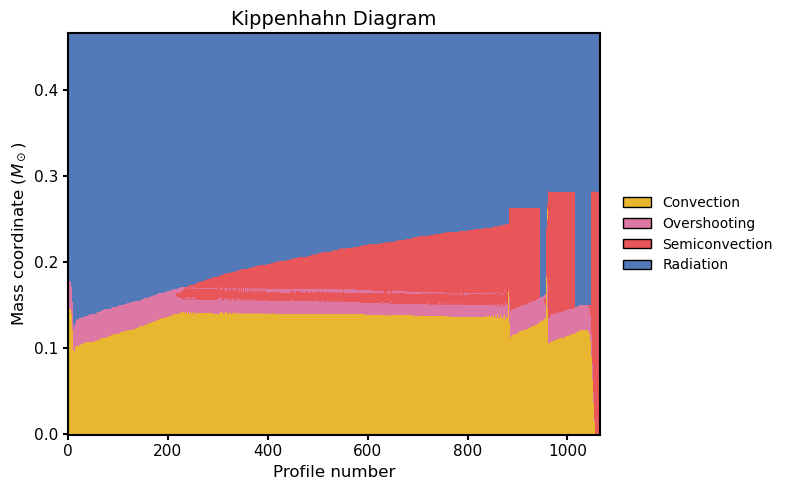

In [25]:
# plotting Kipp with mixing types with semiconvection border defined by the peak of grad L
#range of profiles where the additional semiconvective region is identified
profile_start = 200  
profile_end = 1200

mix_types = []

for prof_num, prof in enumerate(p):
    mass = prof.mass
    mix = prof.mixing_type.copy()
    semi = (prof.gradr_sub_grada > 0) & (prof.gradL_sub_gradr > 0)
    mix[semi] = 3

    #Add region below gradL peak as mixing_type 3 which is semiconvection
    if profile_start <= prof_num <= profile_end:
        peak_idx = np.argmax(prof.gradL)
        below_peak = np.arange(len(mix)) > peak_idx  #grid indices after the Ledoux gradient peak
        protected = (mix == 1) | (mix == 2)  # Preserve regions already classified as convection or overshooting
        mix[below_peak & ~protected] = 3 #Assign the remaining selected regions as semiconvection

    y_grid = np.linspace(mass.min(), mass.max(), 500)
    closest_mix = np.zeros_like(y_grid)

    for i, target_mass in enumerate(y_grid): #assign at each grid point the mixing type of the nearest mass coordinate
        j = np.argmin(np.abs(mass - target_mass))
        closest_mix[i] = mix[j]

    mix_types.append(closest_mix)

mix_types = np.array(mix_types) #mixing types into a 2D array
x = np.arange(len(mix_types))
y = y_grid

plt.figure(figsize=(8, 5))
plt.pcolormesh(x, y, mix_types.T, shading='nearest', cmap=mixing_cmap, vmin=1, vmax=7)

plt.title("Kippenhahn Diagram", fontsize=14)
plt.xlabel("Profile number", fontsize=12)
plt.ylabel(r"Mass coordinate ($M_\odot$)", fontsize=12)

legend_elements = [
    Patch(facecolor='#E9B72F', edgecolor='black', label='Convection'),
    Patch(facecolor='#DD78A5', edgecolor='black', label='Overshooting'),
    Patch(facecolor='#E95659', edgecolor='black', label='Semiconvection'),
    Patch(facecolor='#5479B8', edgecolor='black', label='Radiation')]

plt.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)

plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)

plt.tight_layout()
plt.savefig("CPM_os_mixtype2.png")
plt.show()

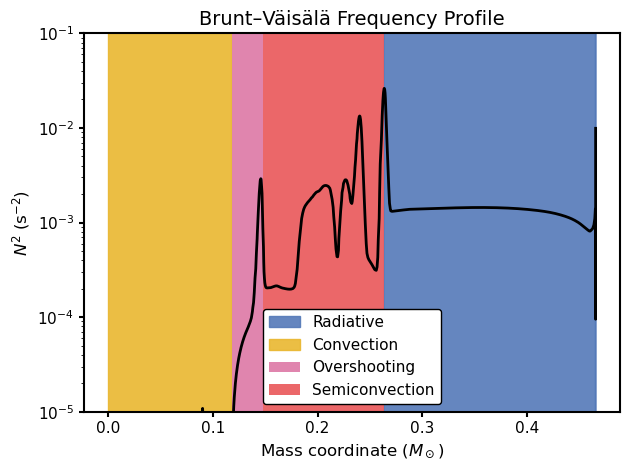

In [99]:
# Brunt–Väisälä and mixing type
i = 900 #coose MESA profile

mass = p[i].mass
mix = p[i].mixing_type.copy()
semi = (p[i].gradr_sub_grada > 0) & (p[i].gradL_sub_gradr > 0) # Identify Kato semiconvective regions
mix[semi] = 3

#Extend the semiconvective classification below the peak of the Ledoux gradient
peak_idx = np.argmax(p[i].gradL)
below_peak = np.arange(len(mix)) > peak_idx
protected = (mix == 1) | (mix == 2) #preserve regions classified as convection or overshooting
mix[below_peak & ~protected] = 3#Assign the remaining selected regions as semiconvection

#different mixing regions
conv = (mix == 1)
os = (mix == 2)
semi = (mix == 3)
rad = (mix == 7)


plt.plot(mass, p[i].brunt_N2, color='black', linewidth=2)
# Shade the regions according to their mixing classification
plt.fill_between(mass, p[i].brunt_N2.min(), 0.1, where=rad, alpha=0.9, color='#5479B8', label='Radiative')
plt.fill_between(mass, p[i].brunt_N2.min(), 0.1, where=conv, alpha=0.9, color='#E9B72F', label='Convection')
plt.fill_between(mass, p[i].brunt_N2.min(), 0.1, where=os, alpha=0.9, color='#DD78A5', edgecolor='none', label='Overshooting')
plt.fill_between(mass, p[i].brunt_N2.min(), 0.1, where=semi, alpha=0.9, color='#E95659', edgecolor='none', label='Semiconvection')

plt.yscale('log')
plt.title('Brunt–Väisälä Frequency Profile', fontsize=14)
plt.xlabel(r'Mass coordinate ($M_\odot$)', fontsize=12)
plt.ylabel(r'$N^2\;(s^{-2})$', fontsize=12)

plt.legend(frameon=True, facecolor='white', framealpha=1, edgecolor='black', fontsize=11)
plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)

plt.ylim(1e-5, 0.1)

plt.tight_layout()
plt.savefig("stage3_brunt.png")
plt.show()

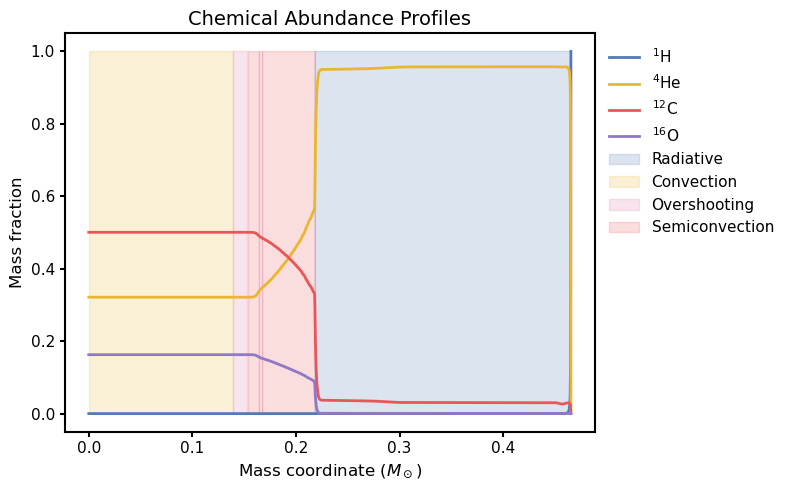

In [83]:
# abundances and mixing type

i = 584 #mesa profile

mass = p[i].mass
mix = p[i].mixing_type.copy()
semi = (p[i].gradr_sub_grada > 0) & (p[i].gradL_sub_gradr > 0) #Kato semicinvective region
mix[semi] = 3

#Extend the semiconvective classification below the peak of the Ledoux gradient
peak_idx = np.argmax(p[i].gradL)
below_peak = np.arange(len(mix)) > peak_idx
protected = (mix == 1) | (mix == 2) #preserve regions classified as convection or overshooting
mix[below_peak & ~protected] = 3#Assign the remaining selected regions as semiconvection

#different mixing regions
conv = (mix == 1)
os = (mix == 2)
semi = (mix == 3)
rad = (mix == 7)

# Plot the chemical abundance profiles
plt.figure(figsize=(8, 5))
plt.plot(p[i].mass, p[i].h1, color=my_colors[0], linewidth=2, label=r'$^1$H')
plt.plot(p[i].mass, p[i].he4, color=my_colors[2], linewidth=2, label=r'$^4$He')
plt.plot(p[i].mass, p[i].c12, color=my_colors[1], linewidth=2, label=r'$^{12}$C')
plt.plot(p[i].mass, p[i].o16, color=my_colors[4], linewidth=2, label=r'$^{16}$O')

#labels
plt.title('Chemical Abundance Profiles', fontsize=14)
plt.xlabel(r'Mass coordinate ($M_\odot$)', fontsize=12)
plt.ylabel('Mass fraction', fontsize=12)

# Shade the regions according to their mixing τυπε
plt.fill_between(mass, 0, 1, where=rad, alpha=0.20, color='#5479B8', label='Radiative')
plt.fill_between(mass, 0, 1, where=conv, alpha=0.2, color='#E9B72F', label='Convection')
plt.fill_between(mass, 0, 1, where=os, alpha=0.2, color='#DD78A5', label='Overshooting')
plt.fill_between(mass, 0, 1, where=semi, alpha=0.2, color='#E95659', label='Semiconvection')

plt.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=True, facecolor='white', framealpha=1, edgecolor='none', fontsize=11)

plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)

plt.tight_layout()
plt.show()

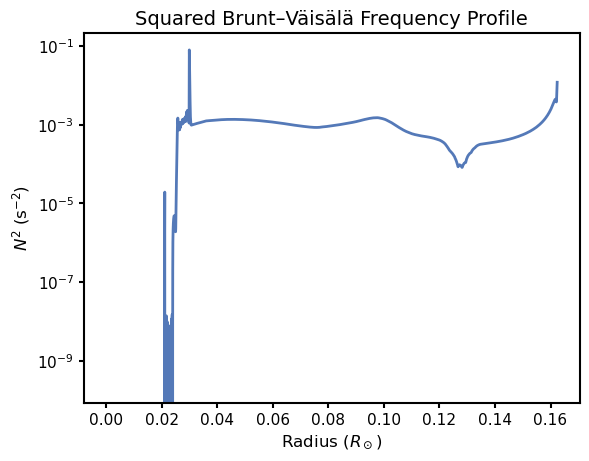

In [90]:
#Brunt Vaisala plot with radius

i =584 #MESA profile

plt.plot(10**p[i].logR, p[i].brunt_N2, linewidth=2)
plt.yscale('log')
plt.title(r'Squared Brunt–Väisälä Frequency Profile', fontsize=14)
plt.xlabel(r'Radius ($R_\odot$)', fontsize=12)
plt.ylabel(r'$N^2\;(s^{-2})$', fontsize=12)

plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)    
plt.show()

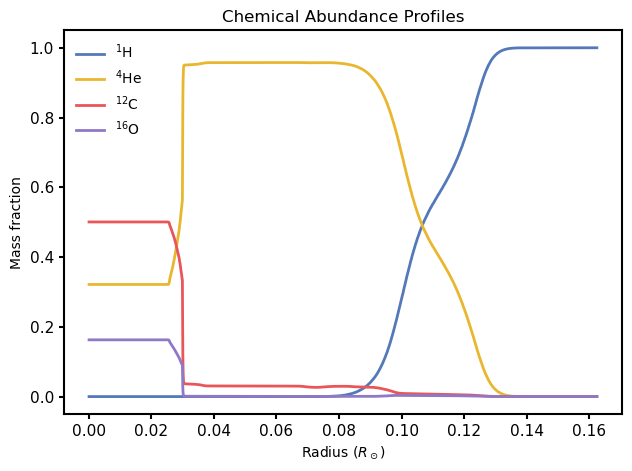

In [91]:
#Abundace plot vs radius
i=584 #MESA profie
plt.plot(p[i].radius, p[i].h1,  color=my_colors[0], linewidth=2, label=r'$^1$H')
plt.plot(p[i].radius, p[i].he4, color=my_colors[2], linewidth=2, label=r'$^4$He')
plt.plot(p[i].radius, p[i].c12, color=my_colors[1], linewidth=2, label=r'$^{12}$C')
plt.plot(p[i].radius, p[i].o16, color=my_colors[4], linewidth=2, label=r'$^{16}$O')

plt.title('Chemical Abundance Profiles')
plt.xlabel(r'Radius ($R_\odot$)')
plt.ylabel('Mass fraction')
plt.legend(frameon=False)

plt.tight_layout()
plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)    
plt.show()

In [316]:
#calculating boyancy radius

prof = p[585]  #MESA Profile

r = np.array(prof.radius)
N2 = np.array(prof.brunt_N2)
idx = np.argsort(r) #sort the radius because it's inversed
r = r[idx]
N2 = N2[idx]
g_cavity = (N2 > 0) #excluding the convective part

first_rad_idx = np.where(g_cavity)[0][0] #find the first radius where N^2 becomes positive
r1 = r[first_rad_idx]
r_after_r1 = r[first_rad_idx:] #select structure from this point onwards
N2_after_r1 = N2[first_rad_idx:]

g_cavity = N2_after_r1 > 0
r_rad = r_after_r1[g_cavity]
N2_rad = N2_after_r1[g_cavity]


#integration
N_shell = np.sqrt(N2_rad)
integrand = N_shell/ r_rad
W = np.zeros_like(r_rad)
W[1:] = np.cumsum(0.5 * (integrand[1:] + integrand[:-1]) * np.diff(r_rad))


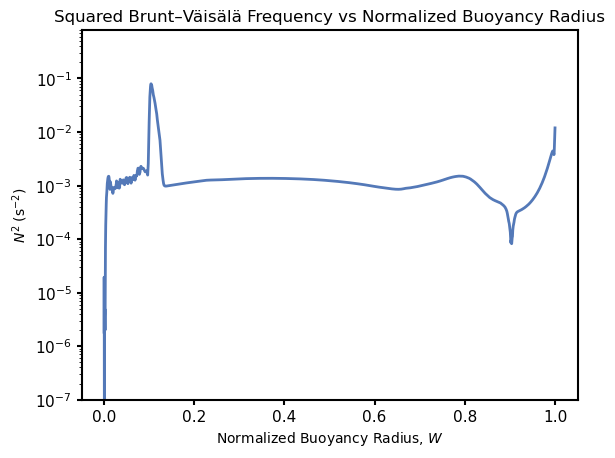

In [317]:
#Brunt Vaisala plot (with boyancy radius)
plt.plot(W/W[-1],N2_rad, linewidth=2)
plt.yscale('log')

plt.title(r'Squared Brunt–Väisälä Frequency vs Normalized Buoyancy Radius')
plt.xlabel(r'Normalized Buoyancy Radius, $W$')
plt.ylabel(r'$N^2\,(s^{-2})$')

#plt.axvline(0.123, color='#DD78A5', linestyle = '--', alpha = 0.8)
# plt.axvline(0.23, color='#DD78A5', linestyle = '--', alpha = 0.8)

plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)
plt.ylim(1e-7,0.8)

#plt.savefig("stage3_boyancy.png")
plt.show()

In [207]:
#read GYRE summary data
s = pg.read_output('/home/gpriniot/Downloads/gyre-9.0/new_sdb/summary.h5')
print(s.meta)
print(s)

{'freq_units': np.bytes_(b'UHZ'), 'label': np.bytes_(b'')}
        E                 E_g                 E_norm         ...  l  n_g n_pg
------------------ ------------------ ---------------------- ... --- --- ----
0.9999999999999999 0.9991728370428034 1.0060354202205712e-10 ...   1 204 -204
               1.0    0.9986520513275 1.1690456313820103e-10 ...   1 203 -203
               1.0 0.9989552237588705 1.1027087695559257e-10 ...   1 202 -202
               1.0 0.9994787422563797  9.744683071591967e-11 ...   1 201 -201
               1.0 0.9997104241403785  9.004697842014591e-11 ...   1 200 -200
1.0000000000000002 0.9997981759459819  8.515691993652967e-11 ...   1 199 -199
               1.0 0.9998267286207196  8.237822981665705e-11 ...   1 198 -198
0.9999999999999998 0.9998202534911289  8.254458442823306e-11 ...   1 197 -197
               1.0  0.999775392293915  8.705577521661815e-11 ...   1 196 -196
               1.0 0.9996678820915993  9.570917862246383e-11 ...   1 195 -195
     

/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


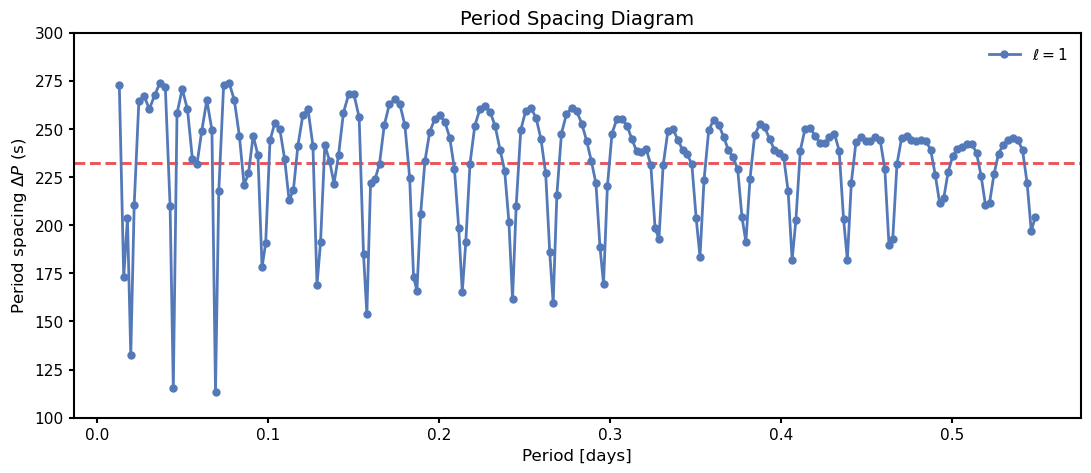

In [222]:
#period spacing diagram
nu = s['freq']
dipole = (s['l'] == 1) #mask for dipole modes
quadrupole = (s['l'] == 2) #mask for dipole modes
P1 = 11.574074074 / nu[dipole]       # days, since nu is in μHz
idx = np.argsort(P1)
P1 = P1[idx]
delta_P1  = np.diff(P1)*24*3600

P2 = 11.574074074 / nu[quadrupole]   # days, since nu is in μHz
idx2 = np.argsort(P2)
P2 = P2[idx2]
delta_P2  = np.diff(P2)*24*3600

Pi_0 = 328.71

delta_P1_as = Pi_0 / np.sqrt(2)
delta_P2_as = Pi_0 / np.sqrt(6)

plt.figure(figsize=(13, 5))
plt.axhline(delta_P1_as,color='#E95659', linestyle='--',  linewidth=2.1)

plt.plot(0.5 * (P1[1:] + P1[:-1]),delta_P1,marker='o',color='#5479B8',linewidth=2,markersize=5,label=r'$\ell=1$')

# plt.plot( 0.5 * (P2[1:] + P2[:-1]),delta_P2,marker='o', color='#E95659',linewidth=2, markersize=5, label=r'$\ell=2$')

plt.title('Period Spacing Diagram', fontsize=14)
plt.xlabel('Period [days]', fontsize=12)
plt.ylabel(r'Period spacing $\Delta P$ (s)', fontsize=12)
plt.legend(frameon=False, fontsize=11)

plt.ylim(100,300)
plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)

plt.show()

/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


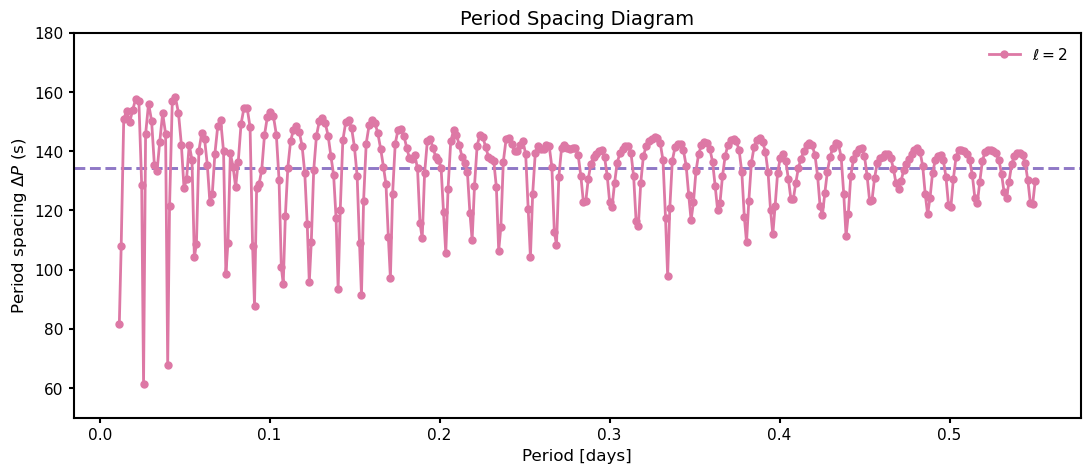

In [223]:
#period spacing diagram
nu = s['freq']
dipole = (s['l'] == 1) #mask for dipole modes
quadrupole = (s['l'] == 2) #mask for quadrupole modes
P1 = 11.574074074 / nu[dipole]       # days, since nu is in μHz
idx = np.argsort(P1)
P1 = P1[idx]
delta_P1  = np.diff(P1)*24*3600

P2 = 11.574074074 / nu[quadrupole]   # days, since nu is in μHz
idx2 = np.argsort(P2)
P2 = P2[idx2]
delta_P2  = np.diff(P2)*24*3600

Pi_0 = 328.71

delta_P1_as = Pi_0 / np.sqrt(2)
delta_P2_as = Pi_0 / np.sqrt(6)

plt.figure(figsize=(13, 5))
plt.axhline(  delta_P2_as,color=my_colors[4], linestyle='--', linewidth=2.1)

# plt.plot(0.5 * (P1[1:] + P1[:-1]),delta_P1,marker='o',color='#5479B8',linewidth=2,markersize=5,label=r'$\ell=1$')

plt.plot( 0.5 * (P2[1:] + P2[:-1]),delta_P2,marker='o', color=my_colors[3],linewidth=2, markersize=5, label=r'$\ell=2$')

plt.title('Period Spacing Diagram', fontsize=14)
plt.xlabel('Period [days]', fontsize=12)
plt.ylabel(r'Period spacing $\Delta P$ (s)', fontsize=12)
plt.legend(frameon=False, fontsize=11)

plt.ylim(50,180)
plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)
plt.show()

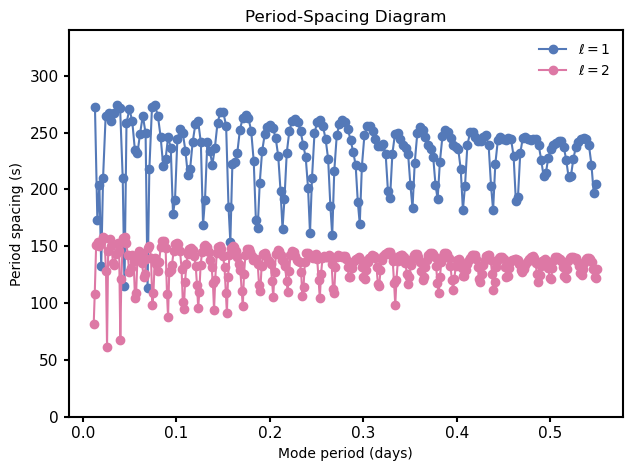

In [103]:
# Period-spacing diagram
nu = s['freq']
dipole = (s['l'] == 1) 
quadrupole = (s['l'] == 2)

#Convert the frequencies to periods in days, sort them and find the spacings in seconds
P1 = 11.574074074 / nu[dipole]
idx = np.argsort(P1)
P1 = P1[idx]
delta_P1 = np.diff(P1) * 24 * 3600
P2 = 11.574074074 / nu[quadrupole]
idx2 = np.argsort(P2)
P2 = P2[idx2]
delta_P2 = np.diff(P2) * 24 * 3600

#plot
plt.plot(0.5 * (P1[1:] + P1[:-1]), delta_P1, marker='o', color=my_colors[0], label=r'$\ell=1$')
plt.plot(0.5 * (P2[1:] + P2[:-1]), delta_P2, marker='o', color=my_colors[3], label=r'$\ell=2$')

plt.xlabel('Mode period (days)')
plt.ylabel('Period spacing (s)')
plt.title('Period-Spacing Diagram')
plt.legend(frameon=False)

plt.ylim(0, 340)

plt.tight_layout()

plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)
plt.show()

/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


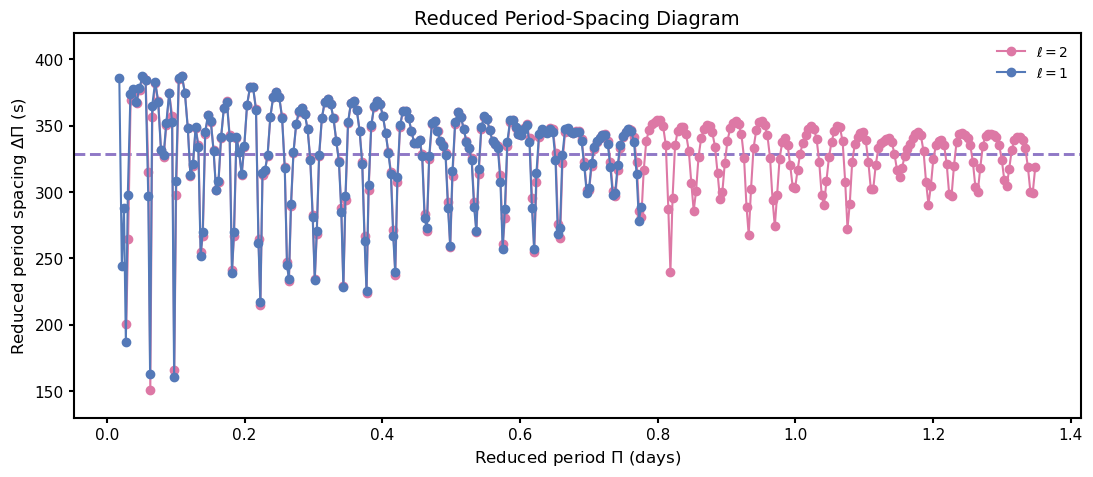

In [231]:
#reduced period spacing diagram
delta_P1_reduced = delta_P1*np.sqrt(2) #multiply by sqrt(l(l+1)) to get the reduced period spacings
delta_P2_reduced = delta_P2*np.sqrt(6)

#plot
plt.figure(figsize=(13, 5))

plt.axhline(328.71, color=my_colors[4], linestyle='--', linewidth=2.1) #asymptotic value

plt.plot((0.5*(P2[1:]+P2[:-1]))*np.sqrt(6), delta_P2_reduced, marker = "o", color=my_colors[3], label=r'$\ell=2$')
plt.plot((0.5*(P1[1:]+P1[:-1]))*np.sqrt(2), delta_P1_reduced ,marker = "o",color=my_colors[0], label=r'$\ell=1$')
plt.xlabel(r'Reduced period $\Pi$ (days)',  fontsize=12)
plt.ylabel(r'Reduced period spacing $\Delta\Pi$ (s)',  fontsize=12)
plt.title('Reduced Period-Spacing Diagram',  fontsize=14)
plt.legend(frameon=False)

plt.ylim(130,420)
# plt.xlim(0.1, 0.45)

plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)
plt.show()

In [243]:
#reading GYRE details files
m = {}
for j in s['n_g'][dipole]:
    m[j] = pg.read_output(f'/home/gpriniot/Downloads/gyre-9.0/new_sdb/detail.l1.n-{j}.h5')

z = {}
for k in s['n_g'][quadrupole]:
    z[k] = pg.read_output(f'/home/gpriniot/Downloads/gyre-9.0/new_sdb/detail.l2.n-{k}.h5')

In [244]:
m[60]

As,Gamma_1,M_r,V_2,c_1,dE_dx,prop_type,rho,x,xi_h,xi_r
float64,float64,float64,float64,float64,float64,int32,float64,float64,complex128,complex128
0.0,1.6355319708765295,0.0,100.15574036170258,0.0073312988379117,0.0,0,20896.744464370226,0.0,(0.004793518392740226+0j),(0.004793518392740186+0j)
-7.963441453203125e-12,1.6355322260910334,2.73089033037925e+25,100.15559705042337,0.0073313557953826125,1.0165467919049191e-08,0,20896.5136298631,0.0006003161987524127,(0.004793519496067501+0j),(0.0047935437304907165+0j)
-1.3435101053540577e-11,1.6355325570721035,8.920847684405819e+25,100.15570177172337,0.007331414879223839,2.23800674366892e-08,0,20896.21426972031,0.0008907349993396131,(0.004793529253976337+0j),(0.004793579325431969+0j)
-1.6189135706523996e-11,1.6355327463272635,1.383641498326909e+26,100.15573794718634,0.007331450396438667,2.998748346772516e-08,0,20896.043107589663,0.0010310705206525786,(0.004793538114525872+0j),(0.004793602701933479+0j)
-2.1318926873789207e-11,1.635533144311017,2.5852279632427525e+26,100.15580698479991,0.007331525600694565,4.549083582576808e-08,0,20895.683177154515,0.0012699353440369762,(0.0047935544210433705+0j),(0.004793651133211268+0j)
-2.5913596560559572e-11,1.6355335143185903,3.932461259812401e+26,100.15586423563649,0.007331596031104239,6.016836413964893e-08,0,20895.348534401273,0.001460511128290583,(0.004793570432985398+0j),(0.004793697301890595+0j)
-3.253828929273884e-11,1.6355341276294368,6.481281012050888e+26,100.15597822383019,0.007331711372742508,8.395239780655521e-08,0,20894.793875848503,0.0017251993299687628,(0.004793595881010533+0j),(0.00479377237177071+0j)
-4.2580397250700575e-11,1.63553521115892,1.1943037629568061e+27,100.15613191314283,0.0073319186505487206,1.2618380547464343e-07,0,20893.813961365817,0.0021150859633310747,(0.004793640131307417+0j),(0.004793905718602164+0j)
-5.247499474993641e-11,1.6355363955372293,1.922537978557266e+27,100.15627373607242,0.007332147147131095,1.7331873481180864e-07,0,20892.742883219395,0.00247886329546361,(0.004793690240928195+0j),(0.004794054603277571+0j)


/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/scipy/signal/_peak_finding.py:266: ComplexWarning: Casting complex values to real discards the imaginary part
  value = np.asarray(value, order='C', dtype=np.float64)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


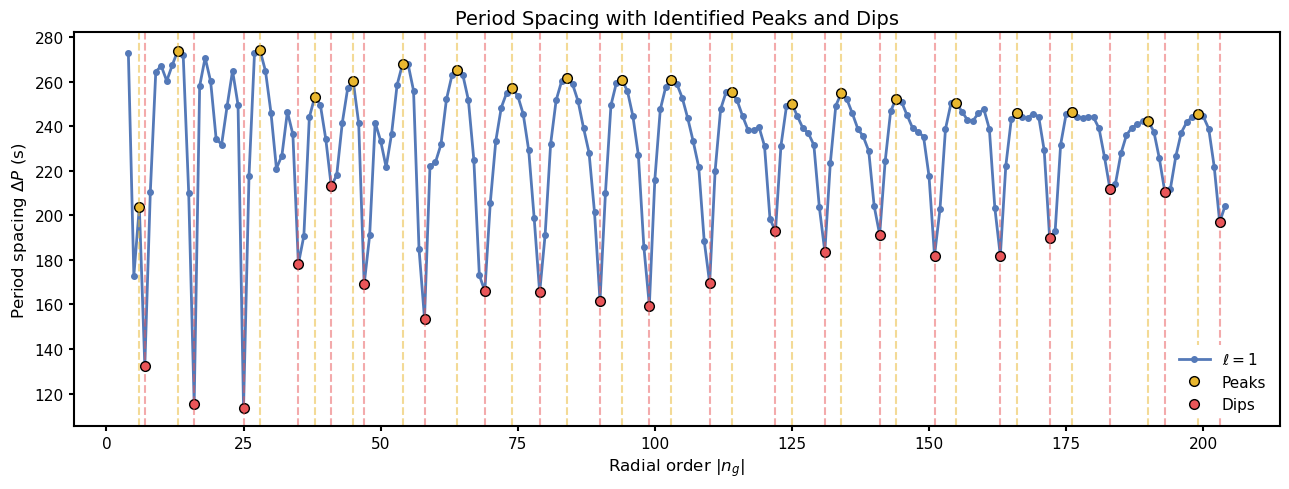

[ 9  9 10  6  6 11 11 10 11  9 11 12  9 10 10 12  9 11 10 10]
mean spacing between dips is 9.8
peaks located at [  6  13  28  38  45  54  64  74  84  94 103 114 125 134 144 155 166 176
 190 199]
dips located at [  7  16  25  35  41  47  58  69  79  90  99 110 122 131 141 151 163 172
 183 193 203]


In [245]:
# finding peaks and dips for dipole modes
x = np.array(s[s['l'] == 1]['n_g'][idx][1:]) #radial orders
y = np.array(delta_P1) #period spacings
peaks, _ = find_peaks(y, distance=6)
dips, _ = find_peaks(-y, distance=6)

#plot
plt.figure(figsize=(13, 5))
plt.plot(x, y, marker='o', color='#5479B8', linewidth=2, markersize=4, label=r'$\ell=1$')

plt.plot(x[peaks], y[peaks], 'o', markerfacecolor='#E9B72F', markeredgecolor='black', markersize=7, label='Peaks')
plt.plot(x[dips], y[dips], 'o', markerfacecolor='#E95659', markeredgecolor='black', markersize=7, label='Dips')

for peak in peaks:
    plt.axvline(x=x[peak], color='#E9B72F', linestyle='--', alpha=0.5)
for dip in dips:
    plt.axvline(x=x[dip], color='#E95659', linestyle='--', alpha=0.5)

plt.title('Period Spacing with Identified Peaks and Dips', fontsize=14)
plt.ylabel(r'Period spacing $\Delta P$ (s)', fontsize=12)
plt.xlabel(r'Radial order $|n_g|$', fontsize=12)

plt.legend(loc='lower right', frameon=True, facecolor='white', framealpha=1, edgecolor='none', fontsize=11)

plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)
plt.tight_layout()
plt.show()

# distance between dips
diff = np.diff(x[dips])
print(diff)
print('mean spacing between dips is', np.mean(diff))
print('peaks located at', x[peaks])
print('dips located at', x[dips])

/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


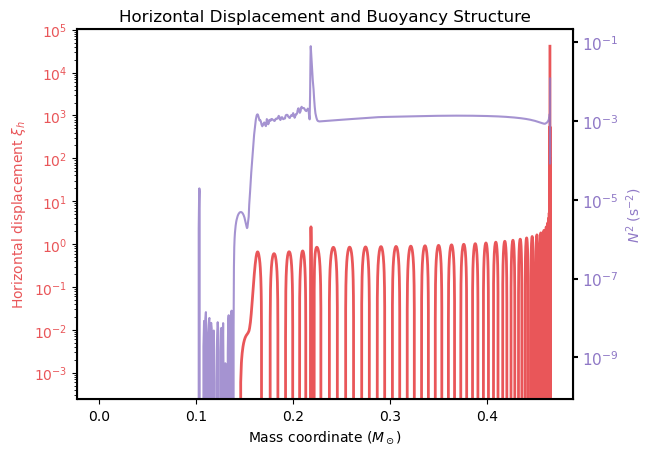

In [247]:
#Horizontal displacement and Brunt Vaisala frequency
fig, ax1 = plt.subplots()

ax1.plot(m[81]['M_r']/1.989e33, m[81]['xi_h'], color=my_colors[1], linewidth=2)
ax1.set_xlabel(r'Mass coordinate ($M_\odot$)')
ax1.set_yscale('log')
ax1.set_ylabel(r'Horizontal displacement $\xi_h$', color=my_colors[1])
ax1.tick_params(axis='y', labelcolor=my_colors[1])

#Add a second y-axis for the squared Brunt–Väisälä frequency from MESA
ax2 = ax1.twinx()
ax2.plot(p[i].mass, p[i].brunt_N2, color=my_colors[4], linewidth=1.5, alpha=0.8)
ax2.set_yscale('log')
ax2.set_ylabel(r'$N^2\;(s^{-2})$', color=my_colors[4])
ax2.tick_params(axis='y', labelcolor=my_colors[4])

plt.title(r'Horizontal Displacement and Buoyancy Structure')
plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)

plt.show()

/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


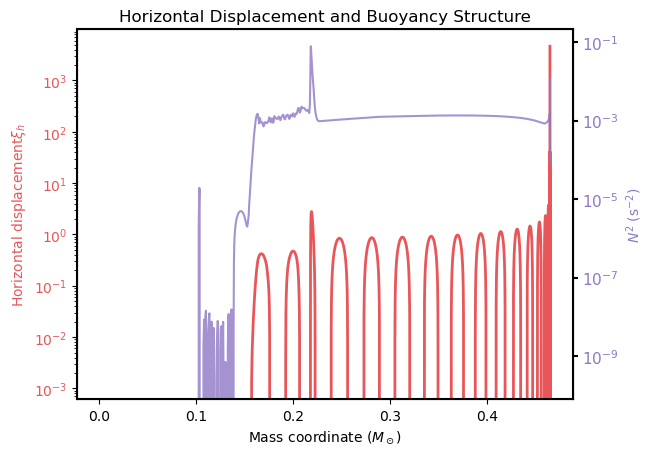

In [314]:
#Horizontal displacement and Brunt Vaisala frequency
fig, ax1 = plt.subplots()

ax1.plot(m[39]['M_r']/1.989e33, m[39]['xi_h'], color=my_colors[1], linewidth=2)
ax1.set_xlabel(r'Mass coordinate ($M_\odot$)')
ax1.set_yscale('log')
ax1.set_ylabel(r'Horizontal displacement$ $\xi_h$', color=my_colors[1])
ax1.tick_params(axis='y', labelcolor=my_colors[1])

#Add a second y-axis for the squared Brunt–Väisälä frequency from MESA
ax2 = ax1.twinx()
ax2.plot(p[i].mass, p[i].brunt_N2, color=my_colors[4], linewidth=1.5, alpha=0.8)
ax2.set_yscale('log')
ax2.set_ylabel(r'$N^2\;(s^{-2})$', color=my_colors[4])
ax2.tick_params(axis='y', labelcolor=my_colors[4])

plt.title(r'Horizontal Displacement and Buoyancy Structure')
plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)

plt.show()

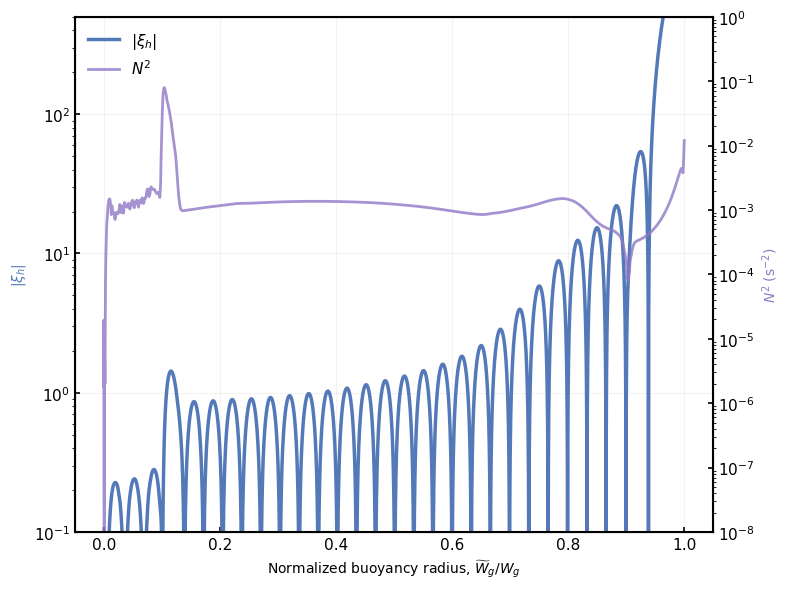

In [378]:
#horizontal displacement and N^2 against normalized buoyancy radius

mode = m[29]#choose GYRE mode
r_mode = np.asarray(mode['x']) * p[i].radius[0]#get radii for it

#Normalize the buoyancy radius and interpolate it onto the GYRE grid
W_norm = W / W[-1]
W_mode = np.interp(r_mode, r_rad, W_norm, left=np.nan, right=np.nan)

# Plot 
fig, ax1 = plt.subplots(figsize=(8, 6))

ax1.plot(W_mode, np.abs(mode['xi_h']), color=my_colors[0], linewidth=2.5, label=r'$|\xi_h|$')
ax1.set_yscale('log')
ax1.set_ylim(1e-1, 500)
ax1.set_xlabel(r'Normalized buoyancy radius, $\widetilde{W}_g/W_g$')
ax1.set_ylabel(r'$|\xi_h|$', color=my_colors[0])

#Add the squared brunt Vaisala frequency on a second y-axis
ax2 = ax1.twinx()
ax2.plot(W_norm, N2_rad, color=my_colors[4], linewidth=2, alpha=0.8, label=r'$N^2$')
ax2.set_yscale('log')
ax2.set_ylim(1e-8, 1)
ax2.set_ylabel(r'$N^2\;(s^{-2})$', color=my_colors[4])


ax1.tick_params(direction='in', width=1.2, labelsize=11)
ax2.tick_params(direction='in', width=1.2, labelsize=11)
ax1.grid(alpha=0.15)
plt.gca().spines[:].set_linewidth(1.5)
fig.tight_layout()
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, fontsize=11, frameon=False)

plt.show()

/tmp/ipykernel_12645/287008818.py:4: ComplexWarning: Casting complex values to real discards the imaginary part
  P1_ech = np.array(P1_ech, dtype=float)
/tmp/ipykernel_12645/287008818.py:13: ComplexWarning: Casting complex values to real discards the imaginary part
  P2_ech = np.array(P2_ech, dtype=float)


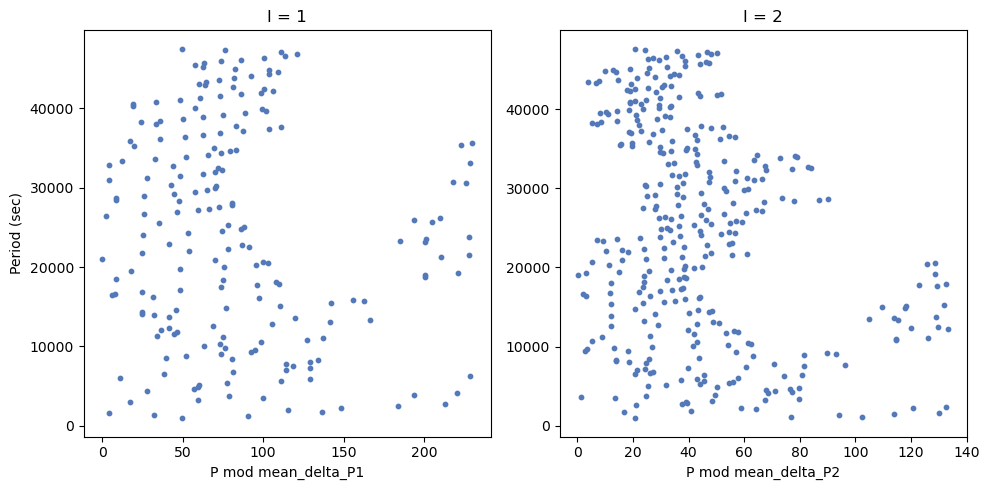

In [283]:
#period echelle diagram

#convert the dipole periods to seconds and sort them
P1_ech = 11.574074074 / nu[dipole]   # days
P1_ech = np.array(P1_ech, dtype=float)
P1_ech = np.sort(P1_ech) * 86400     # seconds
delta_P1 = np.diff(P1_ech) 
mean_Delta_P1 = np.mean(delta_P1)

# Convert the quadrupole periods to seconds and sort them
P2_ech = 11.574074074 / nu[quadrupole]   # days
P2_ech = np.array(P2_ech, dtype=float)
P2_ech = np.sort(P2_ech) * 86400         # seconds
delta_P2 = np.diff(P2_ech) 
mean_Delta_P2 = np.mean(delta_P2) 

fig, axs = plt.subplots(1, 2, figsize=(10, 5))

# l = 1
axs[0].scatter(np.mod(P1_ech, mean_Delta_P1), P1_ech, s=10)
#axs[0].scatter(np.mod(P1_ech, mean_Delta_P1*1.013), P1_ech, s=10)
axs[0].set_title("l = 1")
axs[0].set_xlabel("P mod mean_delta_P1")
axs[0].set_ylabel("Period (sec)")

# l = 2
axs[1].scatter(np.mod(P2_ech, mean_Delta_P2), P2_ech, s=10)
#axs[1].scatter(np.mod(P2_ech, mean_Delta_P2*0.997), P2_ech, s=10)
axs[1].set_title("l = 2")
axs[1].set_xlabel("P mod mean_delta_P2")

plt.tight_layout()
plt.show()

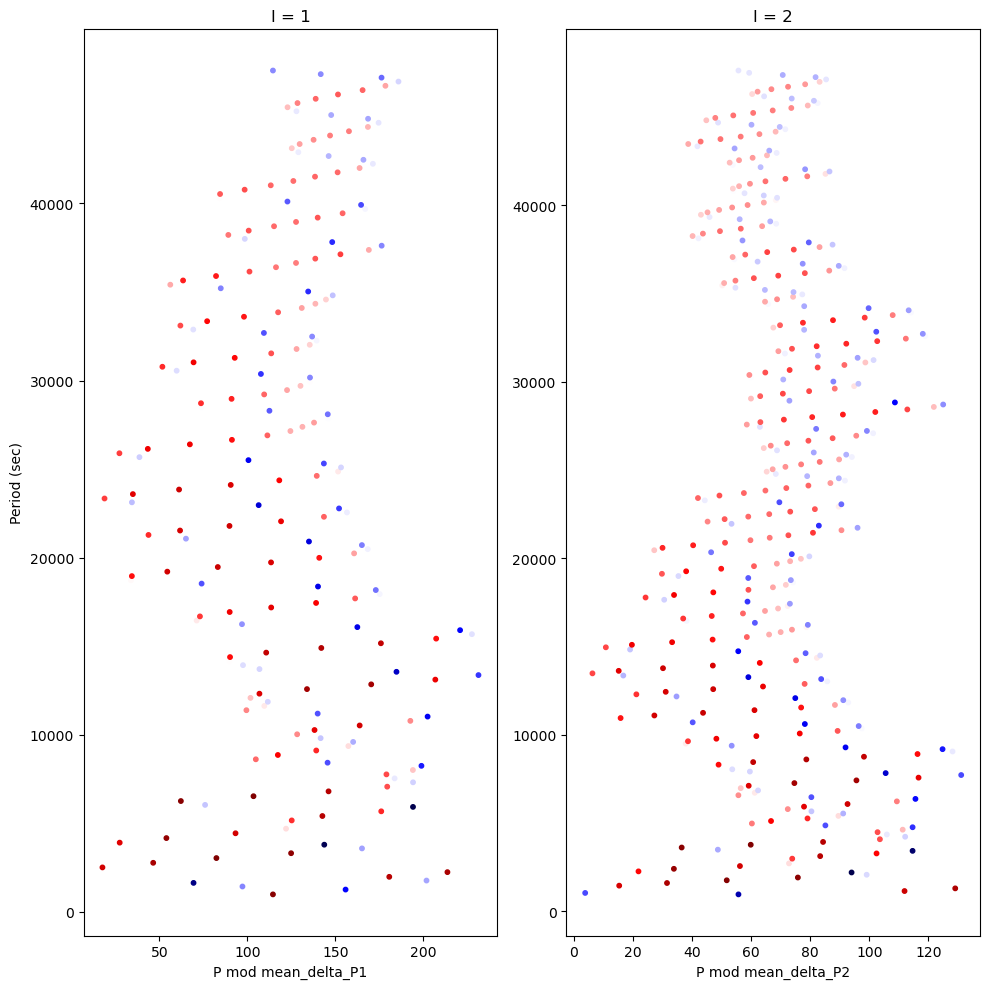

In [284]:
# colored period echelle diagrams
#set a period spacing to each mode for the colour scale
color1 = np.append(delta_P1, delta_P1[-1])
color2 = np.append(delta_P2, delta_P2[-1])

#Center the colour scales on the mean period spacing of each mode degree
norm1 = TwoSlopeNorm(vmin=np.min(color1), vcenter=mean_Delta_P1, vmax=np.max(color1))
norm2 = TwoSlopeNorm(vmin=np.min(color2), vcenter=mean_Delta_P2, vmax=np.max(color2))

#plot
fig, axs = plt.subplots(1, 2, figsize=(10, 10))

# l = 1
axs[0].scatter(np.mod(P1_ech + 65, mean_Delta_P1), P1_ech, c=color1,cmap='seismic', norm=norm1, s=10)
axs[0].set_title("l = 1")
axs[0].set_xlabel("P mod mean_delta_P1")
axs[0].set_ylabel("Period (sec)")

# l = 2
axs[1].scatter(np.mod(P2_ech +35, mean_Delta_P2), P2_ech,c=color2,  cmap='seismic', norm=norm2, s=10)
axs[1].set_title("l = 2")
axs[1].set_xlabel("P mod mean_delta_P2")

plt.tight_layout()
plt.show()

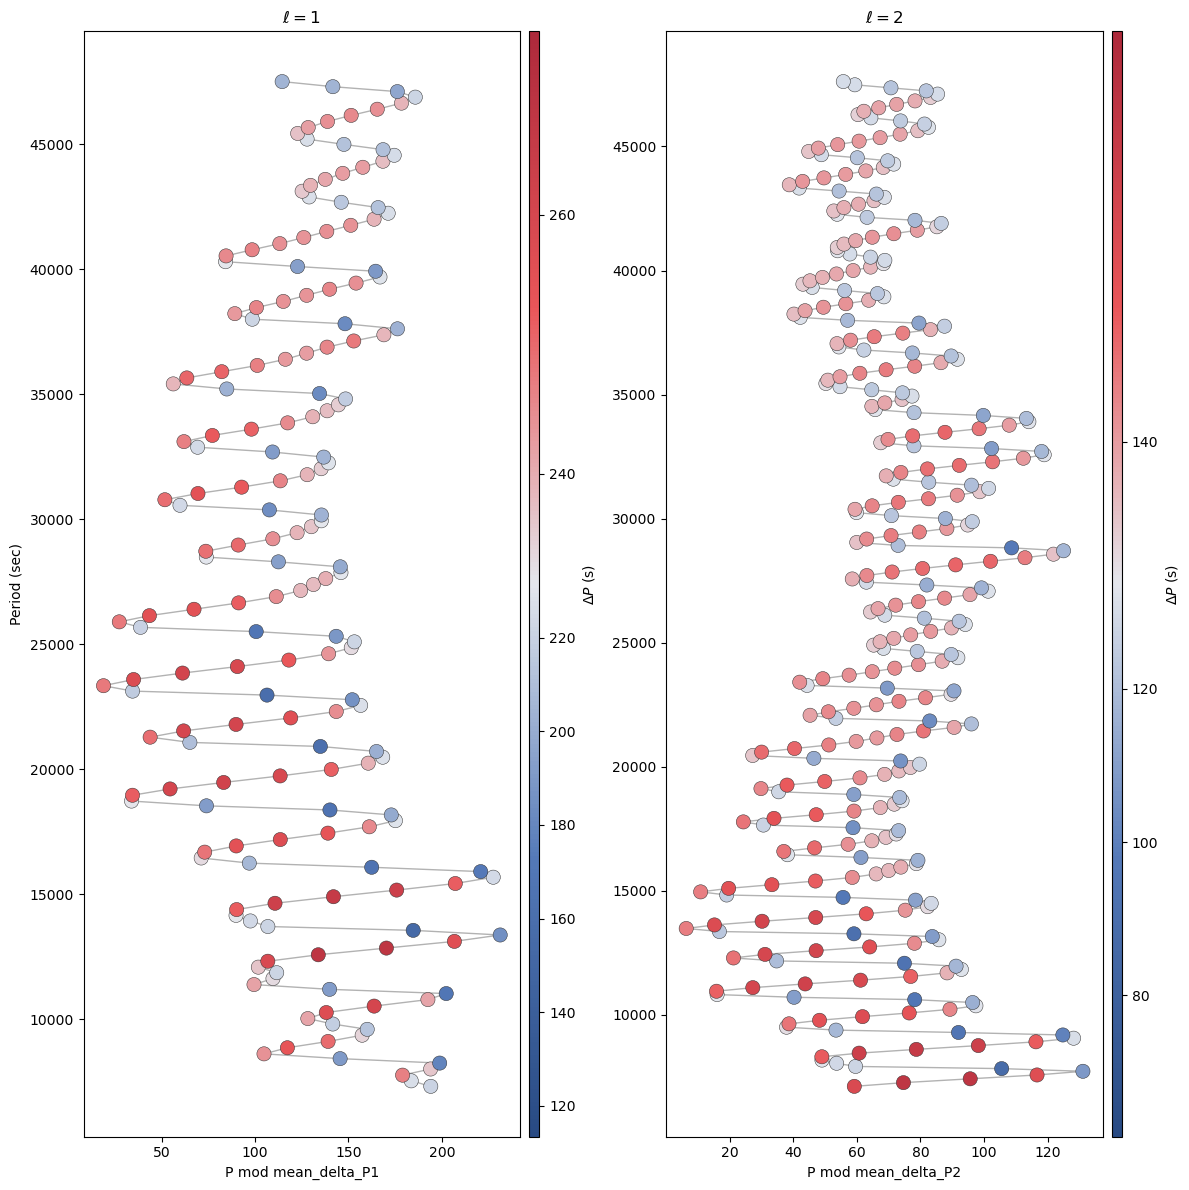

In [310]:
#Coloured period échelle diagrams

# Create a colormap going from my blue to  my red (darkened)
thesis_cmap = LinearSegmentedColormap.from_list('thesis_cmap', ['#284A83', '#5479B8', '#E4E7ED', '#E95659', '#AD293B'], N=256)

# Keep only modes with periods above 7100 seconds
P_min = 7100
keep1 = P1_ech >= P_min
keep2 = P2_ech >= P_min

fig, axs = plt.subplots(1, 2, figsize=(12, 12))

#dipole modes
sc1 = axs[0].scatter(np.mod(P1_ech[keep1] + 65, mean_Delta_P1), P1_ech[keep1], c=color1[keep1], cmap=thesis_cmap, norm=norm1, s=105, edgecolors='#303030', linewidths=0.35, zorder=3)
axs[0].plot(np.mod(P1_ech[keep1] + 65, mean_Delta_P1), P1_ech[keep1], lw=1.0, alpha=0.45, color='#555555', zorder=1)
axs[0].set_title(r'$\ell = 1$')
axs[0].set_xlabel("P mod mean_delta_P1")
axs[0].set_ylabel("Period (sec)")
cbar1 = fig.colorbar(sc1, ax=axs[0], fraction=0.04, pad=0.02, shrink=1.0, aspect=110)
cbar1.set_label(r'$\Delta P$ (s)')

#quadrupole modes
axs[1].plot(np.mod(P2_ech[keep2] + 35, mean_Delta_P2), P2_ech[keep2], lw=1.0, alpha=0.45, color='#555555', zorder=1)
sc2 = axs[1].scatter(np.mod(P2_ech[keep2] + 35, mean_Delta_P2), P2_ech[keep2], c=color2[keep2], cmap=thesis_cmap, norm=norm2, s=105, edgecolors='#303030', linewidths=0.35, zorder=3)
axs[1].set_title(r'$\ell = 2$')
axs[1].set_xlabel("P mod mean_delta_P2")
cbar2 = fig.colorbar(sc2, ax=axs[1], fraction=0.04, pad=0.02, shrink=1.0, aspect=110)
cbar2.set_label(r'$\Delta P$ (s)')

plt.tight_layout()
plt.savefig("simple echelle.png", bbox_inches="tight")
plt.show()

/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/axes/_axes.py:4590: ComplexWarning: Casting complex values to real discards the imaginary part
  c = np.asanyarray(c, dtype=float)


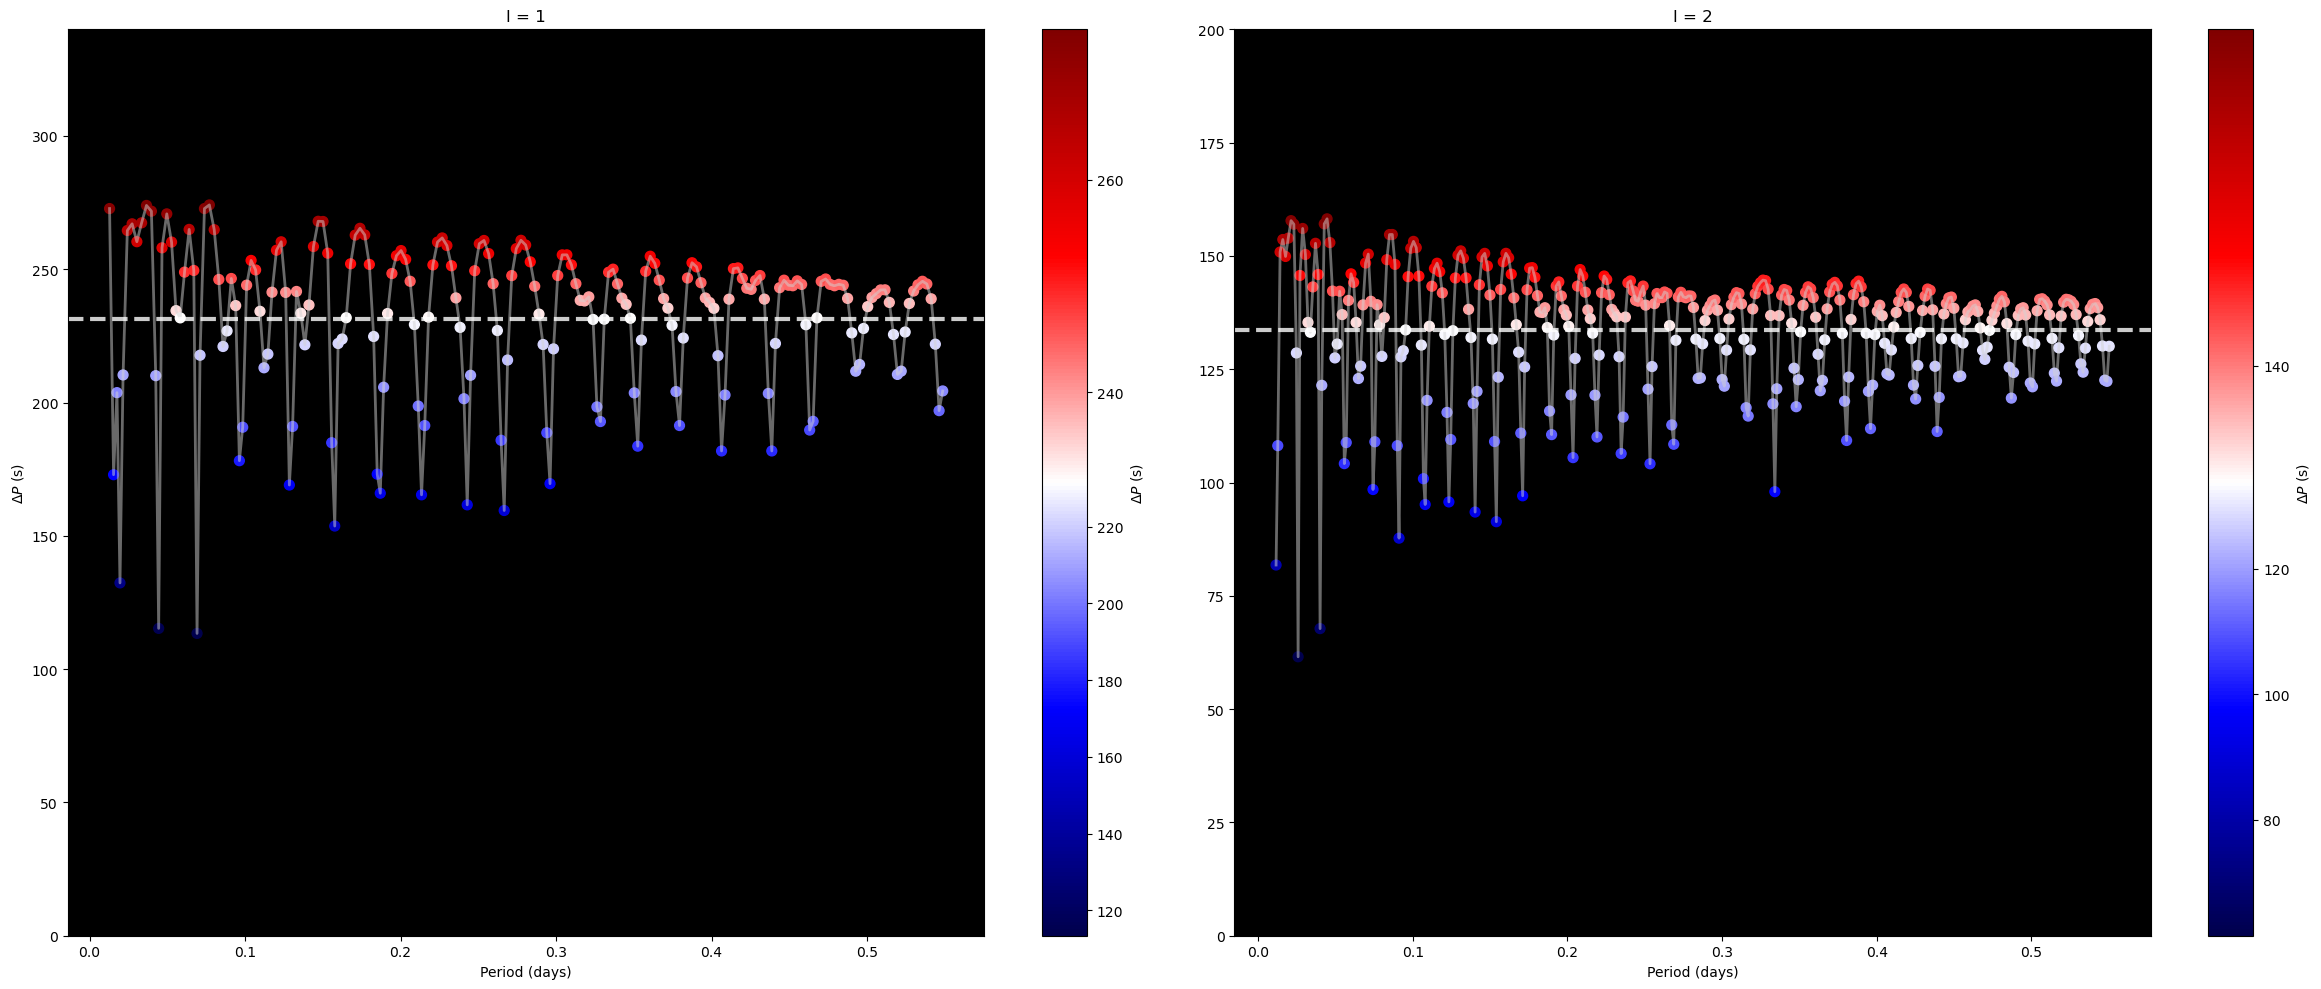

In [154]:
#period spacing diagram with colors (no used)
nu = s['freq']
dipole = (s['l'] == 1)
quadrupole = (s['l'] == 2)
P1 = 11.574074074 / nu[dipole]  # days
P1 = np.sort(P1)
delta_P1  = np.diff(P1)*24*3600

P2 = 11.574074074 / nu[quadrupole] # days
P2 = np.sort(P2)
delta_P2  = np.diff(P2)*24*3600

Pmid1 = 0.5 * (P1[1:] + P1[:-1])
Pmid2 = 0.5 * (P2[1:] + P2[:-1])

fig, axs = plt.subplots(1, 2, figsize=(24,10))

# l = 1
axs[0].plot(Pmid1, delta_P1, lw=2, alpha=0.5, color='lightgray')

sc1 = axs[0].scatter(Pmid1,delta_P1,c=delta_P1,cmap='seismic',norm=norm1,s=50)

axs[0].set_title("l = 1")
axs[0].set_xlabel("Period (days)")
axs[0].set_facecolor('black')
axs[0].set_ylabel(r"$\Delta P$ (s)")
axs[0].set_ylim(0,340)

cbar1 = fig.colorbar(sc1, ax=axs[0])
cbar1.set_label(r'$\Delta P$ (s)')


# l = 2
axs[1].plot(Pmid2, delta_P2, lw=2, alpha=0.5, color='lightgray')

sc2 = axs[1].scatter(Pmid2,delta_P2,c=delta_P2,cmap='seismic', norm=norm2,s=50)

axs[1].set_title("l = 2")
axs[1].set_xlabel("Period (days)")
axs[1].set_facecolor('black')
axs[1].set_ylim(0,200)

cbar2 = fig.colorbar(sc2, ax=axs[1])
cbar2.set_label(r'$\Delta P$ (s)')

axs[0].axhline(y=mean_Delta_P1,xmin=0,xmax=1,c="white",linewidth=3,alpha =0.8, linestyle = "--")
axs[1].axhline(y=mean_Delta_P2,xmin=0,xmax=1,c="white",linewidth=3, alpha =0.8,linestyle = "--")

plt.tight_layout()
plt.show()

/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/axes/_axes.py:4590: ComplexWarning: Casting complex values to real discards the imaginary part
  c = np.asanyarray(c, dtype=float)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/collections.py:197: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


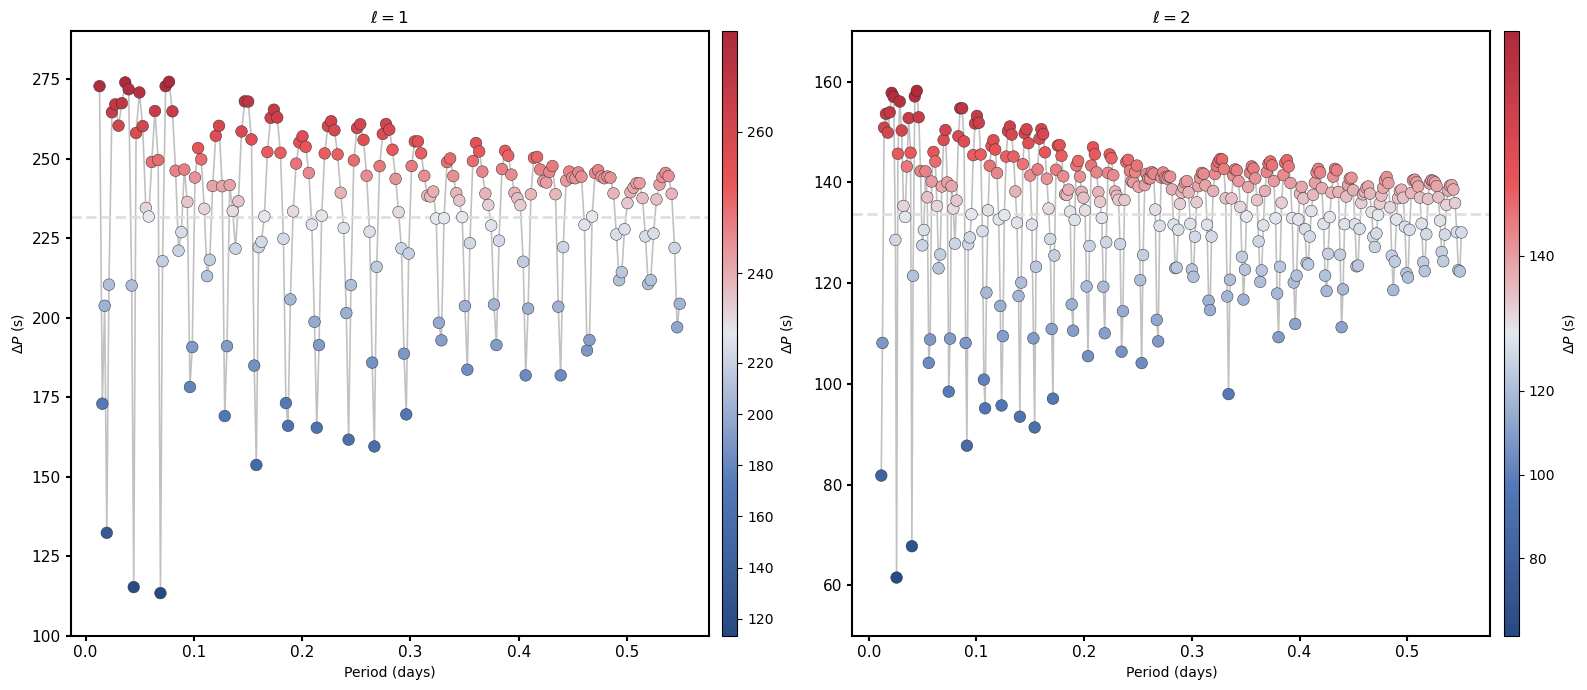

In [311]:
# Coloured period-spacings
nu = s['freq']
dipole = (s['l'] == 1)
quadrupole = (s['l'] == 2)

#Convert the frequencies to periods in days and calculate the spacings in seconds
P1 = 11.574074074 / nu[dipole]
P1 = np.sort(P1)
delta_P1 = np.diff(P1) * 24 * 3600

P2 = 11.574074074 / nu[quadrupole]
P2 = np.sort(P2)
delta_P2 = np.diff(P2) * 24 * 3600

# Use the average period of each pair of modes for the x-axis
Pmid1 = 0.5 * (P1[1:] + P1[:-1])
Pmid2 = 0.5 * (P2[1:] + P2[:-1])

fig, axs = plt.subplots(1, 2, figsize=(16, 7))

#dipole modes
axs[0].plot(Pmid1, delta_P1, lw=1.2, alpha=0.45, color='#777777', zorder=1)
sc1 = axs[0].scatter(Pmid1, delta_P1, c=delta_P1, cmap=thesis_cmap, norm=norm1, s=70, edgecolors='#303030', linewidths=0.35, zorder=3)
axs[0].axhline(y=mean_Delta_P1, color='#DDDDDD', linewidth=2.0, alpha=0.9, linestyle='--')

axs[0].set_title(r'$\ell = 1$')
axs[0].set_xlabel('Period (days)')
axs[0].set_ylabel(r'$\Delta P$ (s)')
axs[0].set_ylim(100, 290)
cbar1 = fig.colorbar(sc1, ax=axs[0], fraction=0.04, pad=0.02, shrink=1.0, aspect=40)
cbar1.set_label(r'$\Delta P$ (s)')

#quadrupole modes
axs[1].plot(Pmid2, delta_P2, lw=1.2, alpha=0.45, color='#777777', zorder=1)
sc2 = axs[1].scatter(Pmid2, delta_P2, c=delta_P2, cmap=thesis_cmap, norm=norm2, s=70, edgecolors='#303030', linewidths=0.35, zorder=3)
axs[1].axhline(y=mean_Delta_P2, color='#DDDDDD', linewidth=2.0, alpha=0.9, linestyle='--')

axs[1].set_title(r'$\ell = 2$')
axs[1].set_xlabel('Period (days)')
axs[1].set_ylim(50, 170)
cbar2 = fig.colorbar(sc2, ax=axs[1], fraction=0.04, pad=0.02, shrink=1.0, aspect=40)
cbar2.set_label(r'$\Delta P$ (s)')

for ax in axs:
    ax.spines[:].set_linewidth(1.5)
    ax.tick_params(width=1.5, labelsize=11)

plt.tight_layout()
plt.savefig("colored_spacings.png", bbox_inches="tight")
plt.show()

In [386]:
#Adding rotational splittings for l=1
def make_rotation_triplets(nus, n_g, rotP_days):
    nus = np.asarray(nus)
    n_g = np.asarray(n_g)

    splitting = 0.5 / rotP_days #calculate the rotational splitting for l=1
    splitting = splitting * 11.574074074   # convert to μHz

    rows = []

    #create the three components for each mode
    for nu0, ng in zip(nus, n_g):

        for m in [-1, 0, 1]:

            nu_split = nu0 + m * splitting #add to the original frequency
            nu_split_cpd = nu_split / 11.574074074
            rows.append({
                "n_g": ng,
                "m": m,
                "nu0_muHz": nu0,
                "splitting_muHz": splitting,
                "nu_split_muHz": nu_split,
                "period_s": 86400 / nu_split_cpd
            })

    return pd.DataFrame(rows)

nu = s['freq'][dipole]
ng = s['n_g'][dipole]

#generate rotational triplets assuming a rotation period of 60 days
triplets = make_rotation_triplets(nu, ng, rotP_days=60)
print(triplets)

     n_g  m                  nu0_muHz  splitting_muHz  \
0    204 -1    21.048652+   0.000000j        0.096451   
1    204  0    21.048652+   0.000000j        0.096451   
2    204  1    21.048652+   0.000000j        0.096451   
3    203 -1    21.139583+   0.000000j        0.096451   
4    203  0    21.139583+   0.000000j        0.096451   
..   ... ..                       ...             ...   
601    4  0   801.100128+   0.000000j        0.096451   
602    4  1   801.100128+   0.000000j        0.096451   
603    3 -1  1025.100773+   0.000000j        0.096451   
604    3  0  1025.100773+   0.000000j        0.096451   
605    3  1  1025.100773+   0.000000j        0.096451   

                nu_split_muHz                    period_s  
0      20.952201+   0.000000j  47727.682004+    0.000000j  
1      21.048652+   0.000000j  47508.980853+    0.000000j  
2      21.145103+   0.000000j  47292.274856+    0.000000j  
3      21.043132+   0.000000j  47521.442410+    0.000000j  
4      21.13958

In [387]:
#Adding rotational splittings for l=2
def make_rotation_quintuplets(nus, n_g, rotP_days):
    nus = np.asarray(nus)
    n_g = np.asarray(n_g)

    splitting = 0.82 / rotP_days #calculate the rotational splitting for l=2
    splitting = splitting * 11.574074074   # convert to μHz

    rows = []

    #create the five components for each mode
    for nu0, ng in zip(nus, n_g):

        for m in [-2,-1, 0,1,2]:

            nu_split = nu0 + m * splitting #add to the original frequency
            nu_split_cpd = nu_split / 11.574074074
            rows.append({
                "n_g": ng,
                "m": m,
                "nu0_muHz": nu0,
                "splitting_muHz": splitting,
                "nu_split_muHz": nu_split,
                "period_s": 86400 / nu_split_cpd
            })

    return pd.DataFrame(rows)

nu_2 = s['freq'][quadrupole]
ng_2 = s['n_g'][quadrupole]

#generate rotational quintuplets assuming a rotation period of 60 days
quintuplets = make_rotation_quintuplets(nu_2, ng_2,rotP_days=60)
print(quintuplets)

      n_g  m                  nu0_muHz  splitting_muHz  \
0     355 -2    21.000671+   0.000000j        0.158179   
1     355 -1    21.000671+   0.000000j        0.158179   
2     355  0    21.000671+   0.000000j        0.158179   
3     355  1    21.000671+   0.000000j        0.158179   
4     355  2    21.000671+   0.000000j        0.158179   
...   ... ..                       ...             ...   
1745    6 -2  1045.364960+   0.000000j        0.158179   
1746    6 -1  1045.364960+   0.000000j        0.158179   
1747    6  0  1045.364960+   0.000000j        0.158179   
1748    6  1  1045.364960+   0.000000j        0.158179   
1749    6  2  1045.364960+   0.000000j        0.158179   

                 nu_split_muHz                    period_s  
0       20.684313+   0.000000j  48345.816454+    0.000000j  
1       20.842492+   0.000000j  47978.907665+    0.000000j  
2       21.000671+   0.000000j  47617.526059+    0.000000j  
3       21.158850+   0.000000j  47261.547675+    0.000000j 

/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


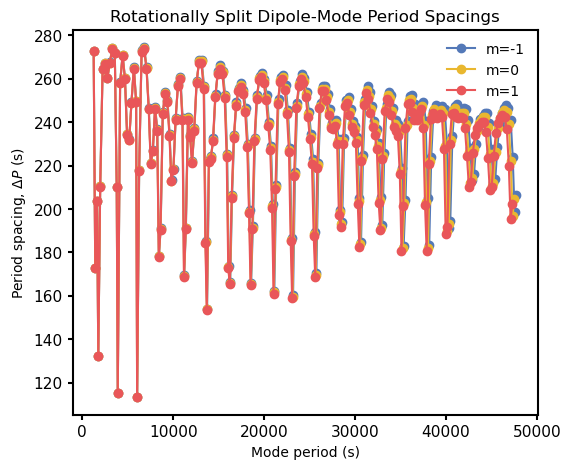

In [394]:
#period spacing diagram for rotationally split modes (l=1)
split_colors = [ my_colors[0],  my_colors[2], my_colors[1], my_colors[4],my_colors[3]] #choose the colours for each component
plt.figure(figsize=(6, 5))

for m in [-1, 0, 1]: #calculate and plot the period spacings separately for each m component
    part = triplets[triplets["m"] == m].copy()
    part = part.sort_values("period_s")
    part["delta_P"] = part["period_s"].diff()
    plt.plot(part["period_s"],part["delta_P"],label=f"m={m}",marker="o", color=split_colors[m+1])

plt.xlabel("Mode period (s)")
plt.ylabel(r"Period spacing, $\Delta P$ (s)")
plt.title(r"Rotationally Split Dipole-Mode Period Spacings")
plt.legend(frameon=False)


plt.gca().spines[:].set_linewidth(1.5)
plt.tick_params(width=1.5, labelsize=11)
plt.show()

/tmp/ipykernel_12645/731862198.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


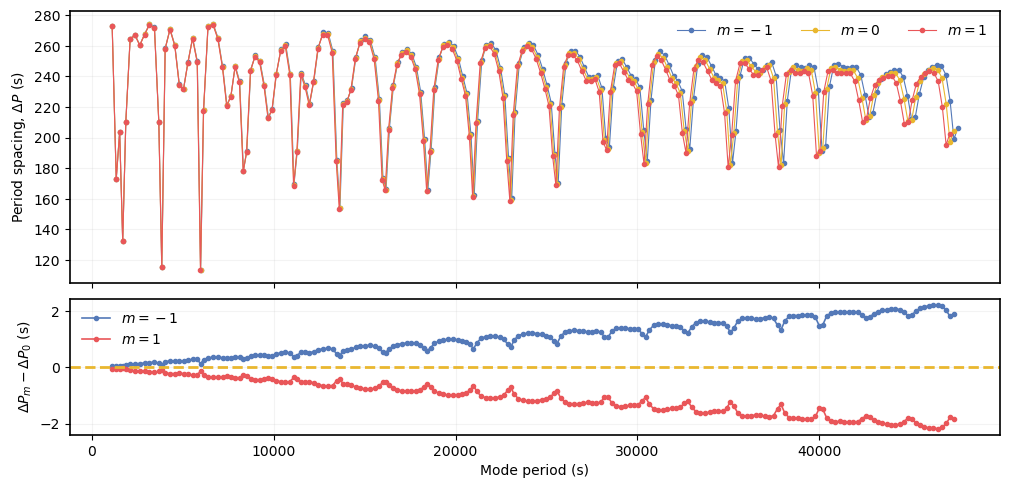

In [413]:
# Rotationally split dipole-mode period spacings

t = triplets.copy()
t["period_s"] = np.real(t["period_s"].to_numpy()).astype(float) #ensure the periods are real numbers

#group by radial order
p = t.pivot(index="n_g", columns="m", values="period_s")
p = p.dropna()
p = p.sort_values(0)

valid = np.abs(np.diff(p.index.to_numpy())) == 1 #keep pairs of modes with consecutive radial orders

#calculate period spacings for the m = 0 modes
P0 = p[0].to_numpy()
dP0 = np.diff(P0)
x0 = (P0[1:] + P0[:-1]) / 2

colors = {-1: my_colors[0], 0: my_colors[2], 1: my_colors[1]} #choose a colour for each component


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1], "hspace": 0.08})

for m in [-1, 0, 1]: #calculate and plot the period spacings for each rotational component
    P = p[m].to_numpy()
    dP = np.diff(P)
    x = (P[1:] + P[:-1]) / 2

    ax1.plot(x[valid], dP[valid], color=colors[m], marker="o", markersize=3, linewidth=0.8, alpha=1, label=fr"$m={m}$")

    if m != 0: 
        ax2.plot(x0[valid], (dP - dP0)[valid], color=colors[m], marker="o", markersize=3, linewidth=1.2, label=fr"$m={m}$")

ax2.axhline(0, color=my_colors[2], ls="--", lw=2)

ax1.set_ylabel(r"Period spacing, $\Delta P$ (s)")
ax2.set_ylabel(r"$\Delta P_m-\Delta P_0$ (s)")
ax2.set_xlabel("Mode period (s)")

ax1.legend(frameon=False, ncol=3)
ax2.legend(frameon=False)

for ax in (ax1, ax2):
    ax.grid(alpha=0.15)
    ax.spines[:].set_linewidth(1.2)
    ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()

/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/gpriniot/miniforge3/envs/MESA/lib/python3.12/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


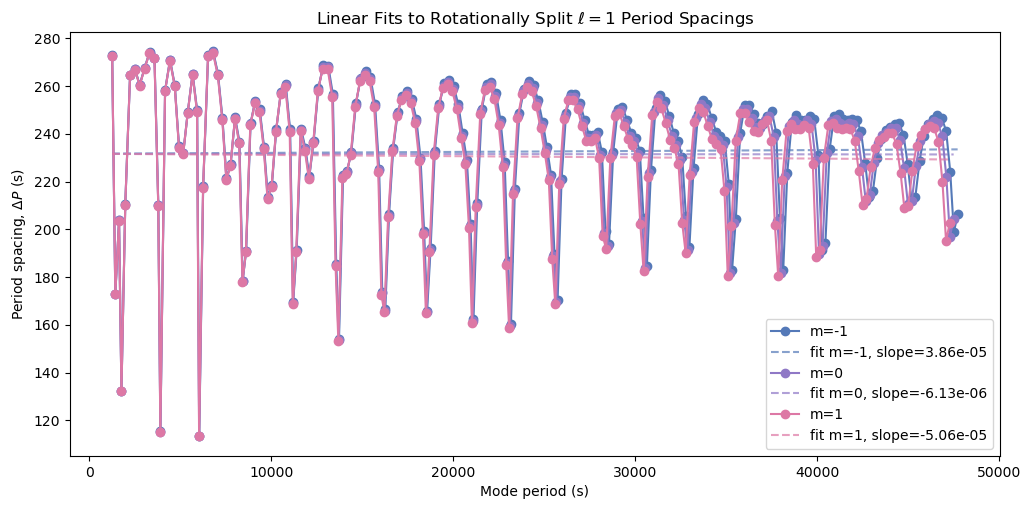

In [402]:
#fitting lines for the period spacing slope
plt.figure(figsize=(12, 5.5))

for m in [-1, 0, 1]: #for each component's sequence
    part = triplets[triplets["m"] == m].copy()
    part = part.sort_values("period_s") #sort by increasing period
    part["delta_P"] = part["period_s"].diff() #calculate spacings

    x = part["period_s"].values[1:] #periods
    y = part["delta_P"].values[1:] #spacings

    #fit best line
    coeff = np.polyfit(x, y, deg=1)
    fit = np.polyval(coeff, x)
    line, = plt.plot(x, y, marker="o", color=split_colors[m+1], label=f"m={m}")

    plt.plot(x, fit,linestyle="--",alpha=0.7,color=line.get_color(),label=f"fit m={m}, slope={np.real(coeff[0]):.2e}")

plt.xlabel("Mode period (s)")
plt.ylabel(r"Period spacing, $\Delta P$ (s)")
plt.title(r"Linear Fits to Rotationally Split $\ell=1$ Period Spacings")
plt.legend()
plt.show()

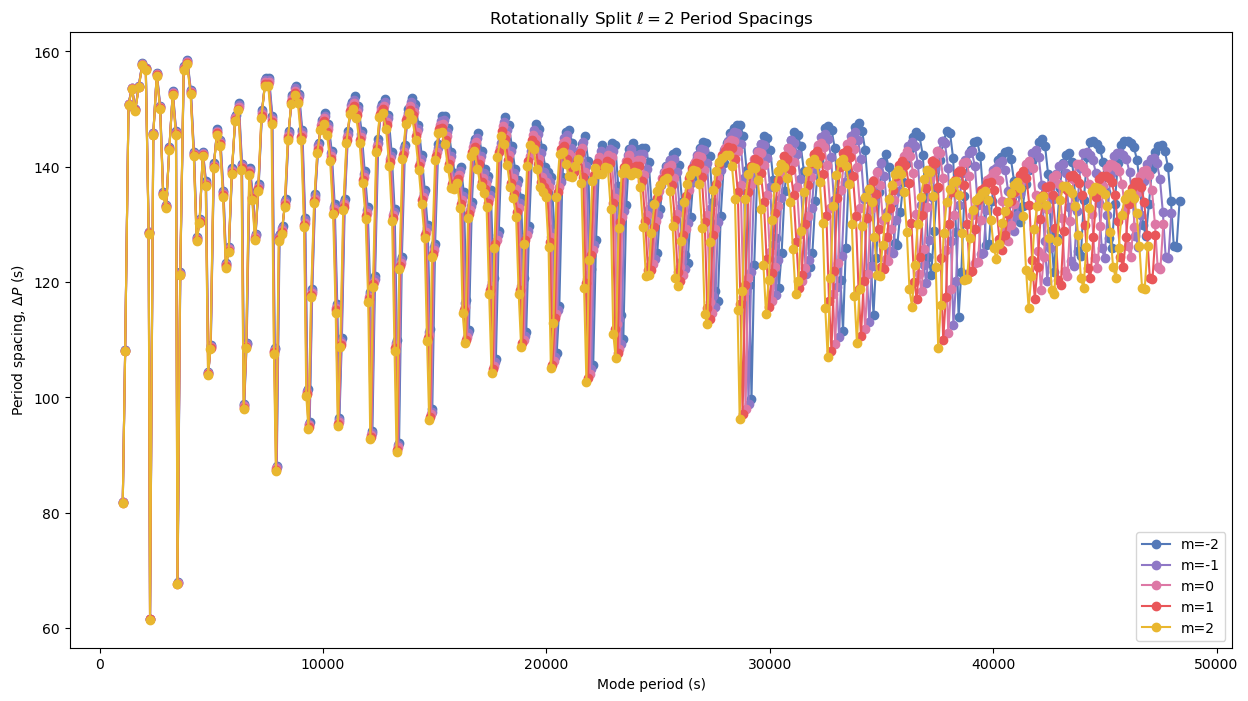

In [231]:
#period spacing diagram for rotationally split modes (l=2)
split_colors = [my_colors[0],  my_colors[4],  my_colors[3], my_colors[1], my_colors[2]] #choose the colours for each component

plt.figure(figsize=(15, 8))

for m in [-2,-1, 0, 1,2]:
    part = quintuplets[quintuplets["m"] == m].copy()
    part = part.sort_values("period_s") #sort by increasing period
    part["delta_P"] = part["period_s"].diff() #calculating spacings

    plt.plot(part["period_s"],part["delta_P"],label=f"m={m}",marker="o", color=split_colors[m+2])

plt.xlabel("Mode period (s)")
plt.ylabel(r"Period spacing, $\Delta P$ (s)")
plt.title(r"Rotationally Split $\ell=2$ Period Spacings")
plt.legend()
plt.show()

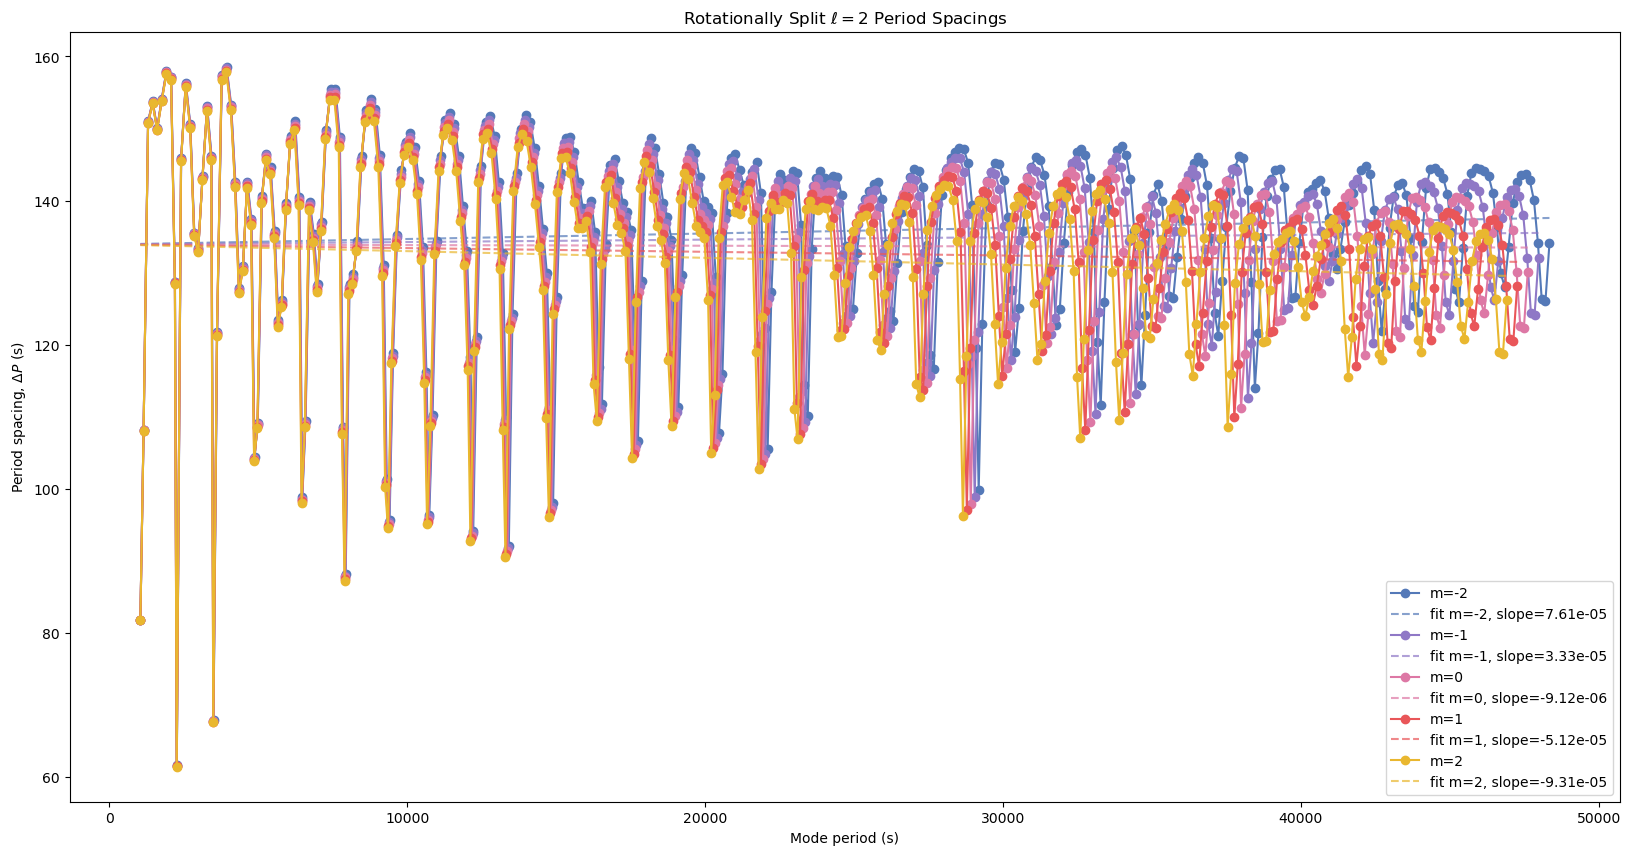

In [232]:
#fitting lines for the period spacing slope

plt.figure(figsize=(20, 10))

for m in [-2,-1, 0, 1,2]: #for each component
    part = quintuplets[quintuplets["m"] == m].copy()
    part = part.sort_values("period_s") #sorting by increasing periods 
    part["delta_P"] = part["period_s"].diff() #calculating spacing

    x = part["period_s"].values[1:] #periods
    y = part["delta_P"].values[1:] #spacings


    #fit best line
    coeff = np.polyfit(x, y, deg=1)
    fit = np.polyval(coeff, x)
    line, = plt.plot(x, y, marker="o",color=split_colors[m+2], label=f"m={m}")

    plt.plot(x, fit,linestyle="--",alpha=0.7,color=line.get_color(),label=f"fit m={m}, slope={np.real(coeff[0]):.2e}")

plt.xlabel("Mode period (s)")
plt.ylabel(r"Period spacing, $\Delta P$ (s)")
plt.title(r"Rotationally Split $\ell=2$ Period Spacings")
plt.legend()
plt.show()

/tmp/ipykernel_12645/3163640880.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


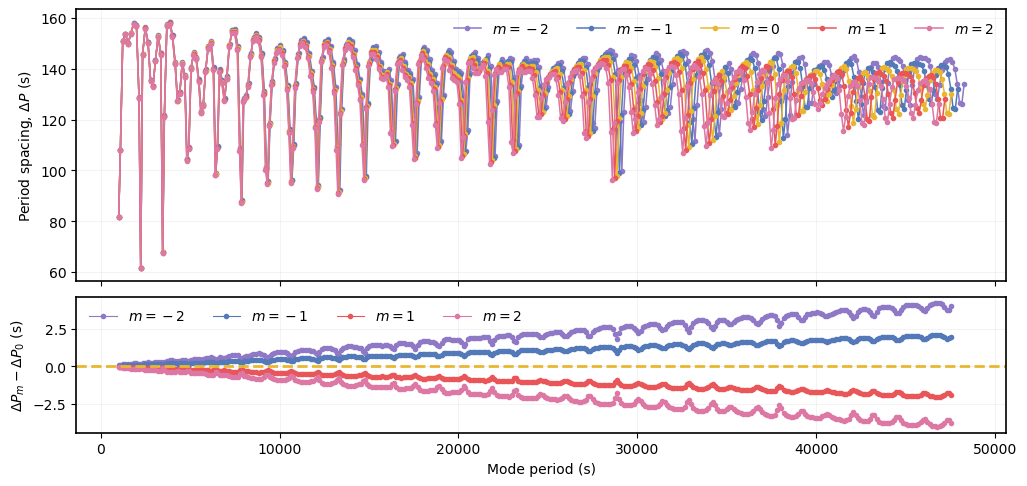

In [412]:

# Rotationally split dipole-mode period spacings

t = quintuplets.copy()
t["period_s"] = np.real(t["period_s"].to_numpy()).astype(float) #ensure real numbers

# Group by radial order
p = t.pivot(index="n_g", columns="m", values="period_s")
p = p.dropna()
p = p.sort_values(0)

valid = np.abs(np.diff(p.index.to_numpy())) == 1 #Keep pairs of modes with consecutive radial orders

# Calculate the period spacings
P0 = p[0].to_numpy()
dP0 = np.diff(P0)
x0 = (P0[1:] + P0[:-1]) / 2

colors = {-2: my_colors[4], -1: my_colors[0], 0: my_colors[2], 1: my_colors[1], 2: my_colors[3]} #choose colors for teh components

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1], "hspace": 0.08})

for m in [-2, -1, 0, 1, 2]:
    P = p[m].to_numpy()
    dP = np.diff(P)
    x = (P[1:] + P[:-1]) / 2

    ax1.plot(x[valid], dP[valid], color=colors[m], marker="o", markersize=3, linewidth=1.1, label=f"$m={m}$")

    if m != 0:
        ax2.plot(x0[valid], (dP - dP0)[valid], color=colors[m], marker="o", markersize=3, linewidth=0.8, label=f"$m={m}$")

ax2.axhline(0, color=my_colors[2], ls="--", lw=2)

ax1.set_ylabel(r"Period spacing, $\Delta P$ (s)")
ax2.set_ylabel(r"$\Delta P_m-\Delta P_0$ (s)")
ax2.set_xlabel("Mode period (s)")

ax1.legend(frameon=False, ncol=5)
ax2.legend(frameon=False, ncol=4)

for ax in (ax1, ax2):
    ax.grid(alpha=0.15)
    ax.spines[:].set_linewidth(1.2)
    ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()

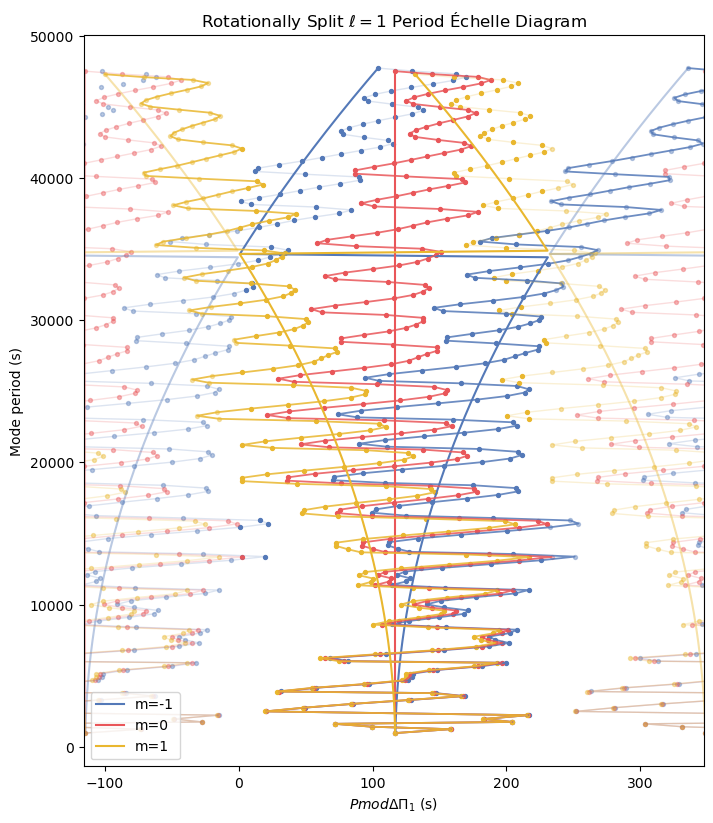

In [235]:
#echelle with rotation for l=1 modes
rotP_days = 60 #period of rotation in days

DeltaPi = mean_Delta_P1   # in seconds

P0 = np.arange(P1_ech.min(), P1_ech.max(), DeltaPi)#asymptotic pure g-modes

splitting = 0.5 / rotP_days          # cycles/day
splitting_Hz = splitting / 86400     # Hz

shift = 67.5 #manual horizontal shift

plt.figure(figsize=(8, 9.5))

for m in [-1, 0, 1]:
    # predicted lines for the rotational components
    nu0 = 1 / P0 #convert to frequencies
    nu_m = nu0 + m * splitting_Hz #apply the splittings
    P_m = 1 / nu_m #convert back to periods

    x_m = np.mod(P_m + shift, DeltaPi) #fold using the mean period spacings

    line, = plt.plot(x_m, P_m, label="m=" + str(m))
    c = line.get_color() #use consistent colors

    plt.plot(x_m - DeltaPi, P_m, color=c, alpha=0.4)
    plt.plot(x_m + DeltaPi, P_m, color=c, alpha=0.4)

    # actual modes
    mask = triplets["m"] == m #keep only modes with the current m value

    P_data = np.array(triplets[mask]["period_s"], dtype=float) #get periods
    x_data = np.mod(P_data + shift, DeltaPi) #fold into echelle diagras

    plt.scatter(x_data, P_data, color=c, s=8)
    plt.scatter(x_data - DeltaPi, P_data, color=c, s=8, alpha=0.4)
    plt.scatter(x_data + DeltaPi, P_data, color=c, s=8, alpha=0.4)

    connect_Pmin = 10000   # adjust manually, period above which the connecting lines can move between copies
    
    idx = np.argsort(P_data) #sort by increasing periods
    P_sorted = P_data[idx]
    x_raw = x_data[idx]
    
    x_connect = np.zeros_like(x_raw)
    x_connect[0] = x_raw[0]
    
    for i in range(1, len(x_raw)):
    
        if P_sorted[i] < connect_Pmin:
            x_connect[i] = x_raw[i] # low periods stay in same copy only
    
        else:
            options = np.array([
                x_raw[i] - DeltaPi,
                x_raw[i],
                x_raw[i] + DeltaPi])
    
            x_connect[i] = options[np.argmin(np.abs(options - x_connect[i-1]))] # high periods go to nearest mode copy
    
    plt.plot(x_connect, P_sorted, color=c, alpha=0.85, lw=1.3)
    plt.plot(x_connect - DeltaPi, P_sorted, color=c, alpha=0.2, lw=1)
    plt.plot(x_connect + DeltaPi, P_sorted, color=c, alpha=0.2, lw=1)

plt.xlabel(r"$P mod \Delta\Pi_1$ (s)")
plt.ylabel("Mode period (s)")
plt.title(r"Rotationally Split $\ell=1$ Period Échelle Diagram")
plt.xlim(-DeltaPi/2, 1.5*DeltaPi)
plt.legend(loc ='lower left')
plt.show()

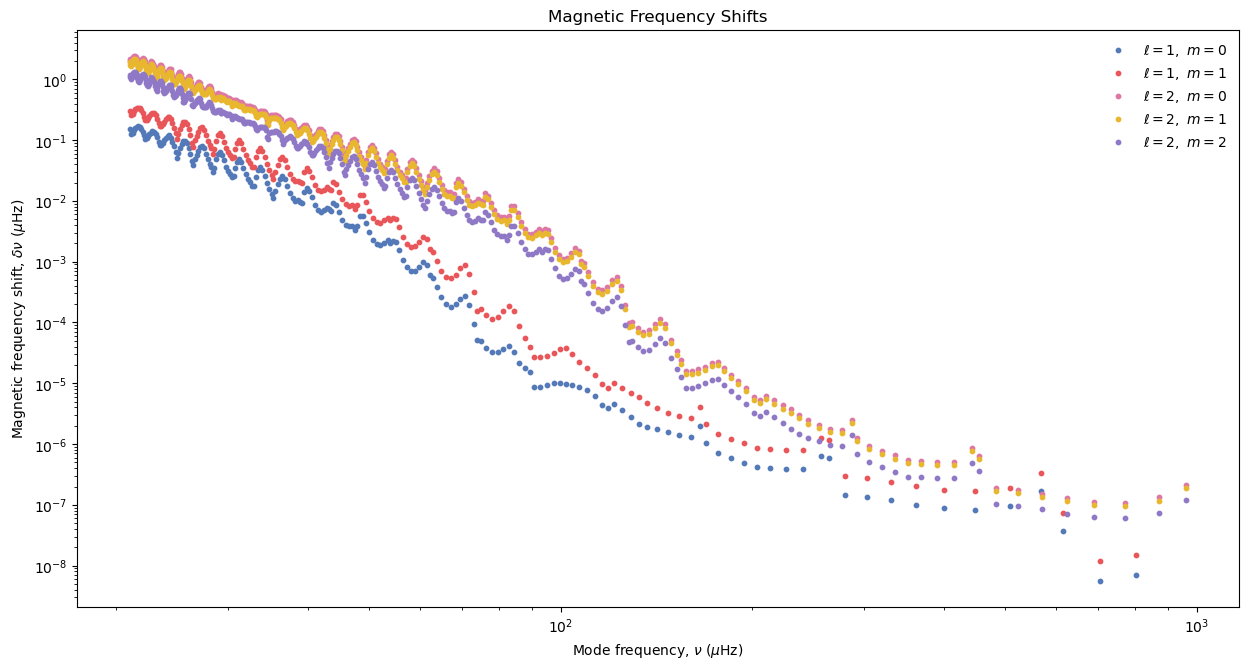

In [463]:
#loading and plotting magnetic shifts from pymagn
magn_shifts = np.load('/home/gpriniot/pymagn-main/data/Zetas/magn_shifts.npz')
d10 = np.array(magn_shifts['d10'][0,0,:,:]) #Dipole modes with m = 0
d11 = np.array(magn_shifts['d11'][0,0,:,:]) #Dipole modes with m = 1
d20 = np.array(magn_shifts['d20'][0,0,:,:]) #Quadrupole modes with m = 0
d21 = np.array(magn_shifts['d21'][0,0,:,:]) #Quadrupole modes with m = 1
d22 = np.array(magn_shifts['d22'][0,0,:,:]) #quadrupole modes with m = 2

def remove_zeros(d): #remove rows where both the frequency and magnetic shift are zero
    d=np.array(d, dtype=float)
    return d[~((d[:,0]==0)&(d[:,1]==0))]

d10=remove_zeros(d10)
d11=remove_zeros(d11)
d20=remove_zeros(d20)
d21=remove_zeros(d21)
d22=remove_zeros(d22)

#plot
plt.figure(figsize=(15, 7.5))

plt.scatter(d10[:,0], d10[:,1], s=10, color=my_colors[0], label=r"$\ell=1,\ m=0$")
plt.scatter(d11[:,0], d11[:,1], s=10, color=my_colors[1], label=r"$\ell=1,\ m=1$")
plt.scatter(d20[:,0], d20[:,1], s=10, color=my_colors[3], label=r"$\ell=2,\ m=0$")
plt.scatter(d21[:,0], d21[:,1], s=10, color=my_colors[2], label=r"$\ell=2,\ m=1$")
plt.scatter(d22[:,0], d22[:,1], s=10, color=my_colors[4], label=r"$\ell=2,\ m=2$")

plt.xscale("log")
plt.yscale("log")

plt.title("Magnetic Frequency Shifts")
plt.xlabel(r"Mode frequency, $\nu$ ($\mu$Hz)")
plt.ylabel(r"Magnetic frequency shift, $\delta\nu$ ($\mu$Hz)")
plt.legend(frameon=False)
plt.show()

In [465]:
# Clean the magnetic shift data before using it
def clean_shift_data(d):
    d = np.array(d, dtype=float) 
    mask = np.isfinite(d).all(axis=1) & (d > 0).all(axis=1) # Keep only finite, positive frequencies and magnetic shifts
    d = d[mask] 
    return d[np.argsort(d[:, 0])] # Sort by increasing frequency

# Clean the data for each mode
d10_plot = clean_shift_data(d10)
d11_plot = clean_shift_data(d11)
d20_plot = clean_shift_data(d20)
d21_plot = clean_shift_data(d21)
d22_plot = clean_shift_data(d22)

# Include both positive and negative m components
mag_sequences = {
    (1, -1): d11_plot,
    (1, 0): d10_plot,
    (1, 1): d11_plot,
    (2, -2): d22_plot,
    (2, -1): d21_plot,
    (2, 0): d20_plot,
    (2, 1): d21_plot,
    (2, 2): d22_plot}

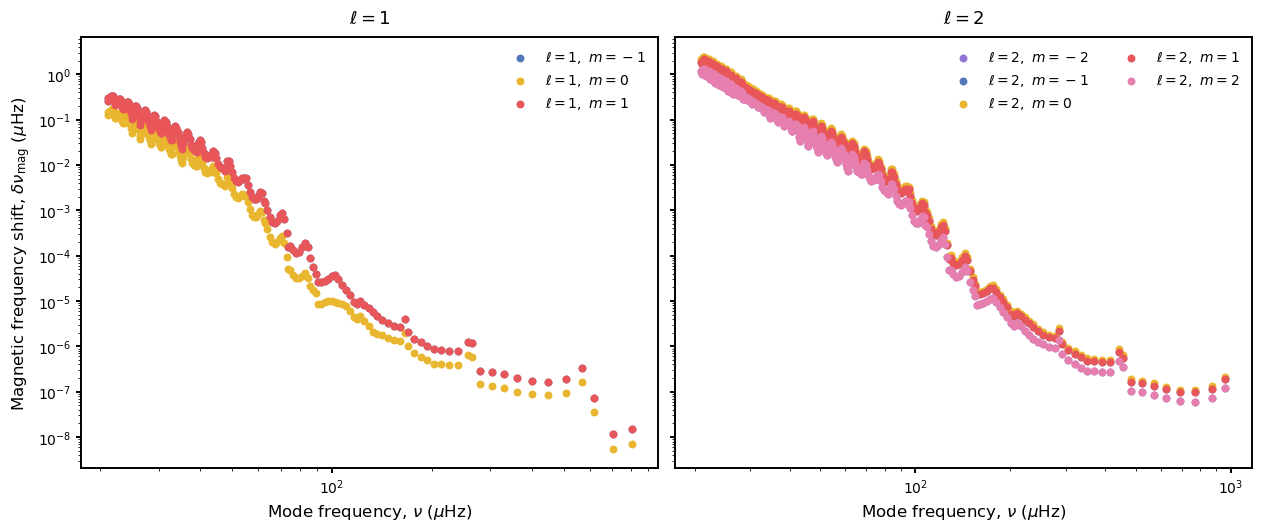

In [466]:
# magnetic frequency shifts

m_colors = {-2: "#9275D8", -1: "#5479B8", 0: "#E9B72F", 1: "#E95659", 2: "#E77FAE"} #choose a colour for each m component

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), sharey=True, constrained_layout=True)

for ell, ax in zip([1, 2], axes): #for each l

    for m in range(-ell, ell + 1): #for each m
        data = mag_sequences[(ell, m)] #get the magnetic shifts for this mode
        ax.scatter(data[:, 0], data[:, 1], s=22, color=m_colors[m], label=r"$\ell=" + str(ell) + ",\ m=" + str(m) + "$")

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel(r"Mode frequency, $\nu$ ($\mu$Hz)", fontsize=12)
    ax.set_title(r"$\ell=" + str(ell) + "$", fontsize=13, pad=10)
    ax.legend(frameon=False, fontsize=10, ncol=1 if ell == 1 else 2)
    ax.tick_params(width=1.4, labelsize=10)

    for spine in ax.spines.values():
        spine.set_linewidth(1.4) #make the axis borders thicker

axes[0].set_ylabel(r"Magnetic frequency shift, $\delta\nu_{mag}$ ($\mu$Hz)", fontsize=12)

plt.show()

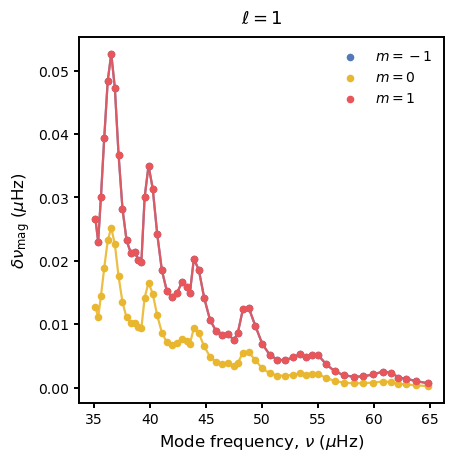

In [470]:
# Zoomed magnetic frequency shifts for dipole modes

#frequency window
nu_min = 35 
nu_max = 65 

fig, ax = plt.subplots(figsize=(6, 4.5), constrained_layout=True)


for m in [-1, 0, 1]:
    data = mag_sequences[(1, m)] #select the dipole modes for this m value
    mask = (data[:, 0] >= nu_min) & (data[:, 0] <= nu_max) #keep frequencies within the window

    x = data[mask, 0] # Frequencies within the selected range
    y = data[mask, 1] # Corresponding magnetic frequency shifts

    idx = np.argsort(x) 
    x = x[idx] #sort the frequencies
    y = y[idx] #keep the shifts in the same order

    ax.plot(x, y, color=m_colors[m], linewidth=1.6, alpha=0.9)
    ax.scatter(x, y, s=20, color=m_colors[m], label="$m=" + str(m) + "$", zorder=3)

ax.set_xlabel(r"Mode frequency, $\nu$ ($\mu$Hz)", fontsize=12)
ax.set_ylabel(r"$\delta\nu_{mag}$ ($\mu$Hz)", fontsize=12)
ax.set_title(r"$\ell=1$", fontsize=13, pad=10)
ax.legend(frameon=False, fontsize=10, ncol=1)
ax.tick_params(width=1.4, labelsize=10)
ax.set_box_aspect(1) #make the plotting area square

for spine in ax.spines.values():
    spine.set_linewidth(1.4) 


plt.show()

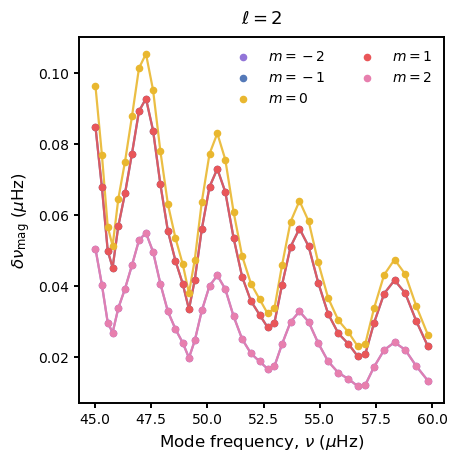

In [471]:
# Zoomed magnetic frequency shifts — quadrupole modes
nu_min = 45 #frequency window
nu_max = 60 

fig, ax = plt.subplots(figsize=(6, 4.5), constrained_layout=True)

for m in [-2, -1, 0, 1, 2]:
    data = mag_sequences[(2, m)] #select the quadrupole modes for this m value
    mask = (data[:, 0] >= nu_min) & (data[:, 0] <= nu_max) #keep frequencies within the window

    x = data[mask, 0] #Frequencies
    y = data[mask, 1] # Corresponding magnetic frequency shifts

    idx = np.argsort(x) 
    x = x[idx] #sort the frequencies
    y = y[idx] #keep the shifts in the same order

    ax.plot(x, y, color=m_colors[m], linewidth=1.6, alpha=0.9)
    ax.scatter(x, y, s=20, color=m_colors[m], label="$m=" + str(m) + "$", zorder=3)

ax.set_xlabel(r"Mode frequency, $\nu$ ($\mu$Hz)", fontsize=12)
ax.set_ylabel(r"$\delta\nu_{mag}$ ($\mu$Hz)", fontsize=12)
ax.set_title(r"$\ell=2$", fontsize=13, pad=10)
ax.legend(frameon=False, fontsize=10, ncol=2)
ax.tick_params(width=1.4, labelsize=10)
ax.set_box_aspect(1)

for spine in ax.spines.values():
    spine.set_linewidth(1.4)

plt.show()

A = 1321.4779193107288


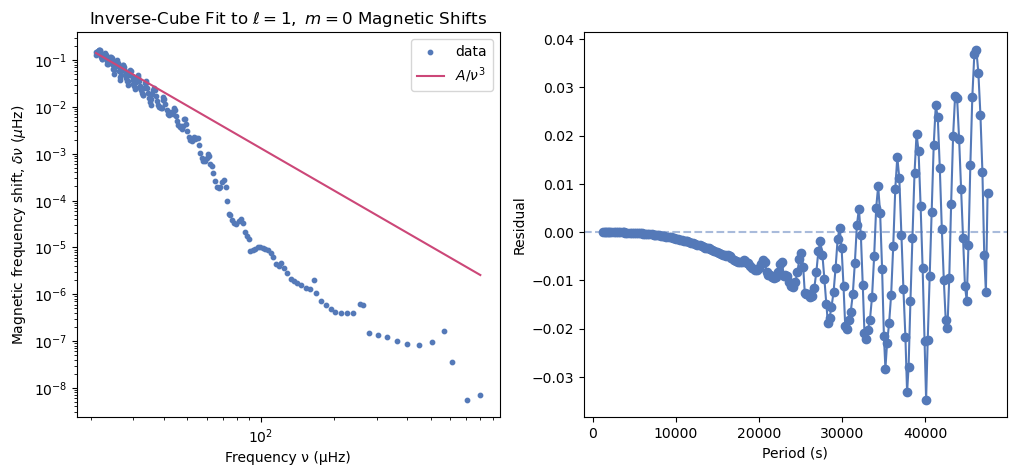

In [472]:
#fitting inverse cube trend for d10
nu = np.array(d10[:, 0], dtype=float) #frequencies
mag_shift = np.array(d10[:, 1], dtype=float) #magnetic shifts

#Remove invalid values
valid = np.isfinite(nu) & np.isfinite(mag_shift) & (nu > 0)
nu = nu[valid]
mag_shift = mag_shift[valid]

# Sort
sort_index = np.argsort(nu)
nu = nu[sort_index]
mag_shift = mag_shift[sort_index]
P = 1e6 / nu #convert frequencies in μHz to periods in seconds

def inv_cube(nu, A):#define the inverse-cube relation
    return A / nu**3


popt, _ = curve_fit(inv_cube, nu, mag_shift) #best fit

A = popt[0] #fitted coefficient
trend = inv_cube(nu, A) 
residual = mag_shift - trend #calculate the difference between the data and the fit

print("A =", A)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.title(r"Inverse-Cube Fit to $\ell=1,\ m=0$ Magnetic Shifts")
plt.scatter(nu, mag_shift, s=10, label="data")
plt.plot(nu, trend, color="#cc4778", label=r"$A/\nu^3$")
plt.yscale("log")
plt.xscale("log")
plt.xlabel("Frequency ν (μHz)")
plt.ylabel(r"Magnetic frequency shift, $\delta\nu$ ($\mu$Hz)")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(P, residual, marker="o")
plt.axhline(0, linestyle="--", alpha=0.5) #Add a reference line at zero residual
plt.xlabel("Period (s)")
plt.ylabel("Residual")

plt.show()


Best-fit A for l=1, m=0: 1.3215e+03
Best-fit A for l=2, m=0: 1.8062e+04


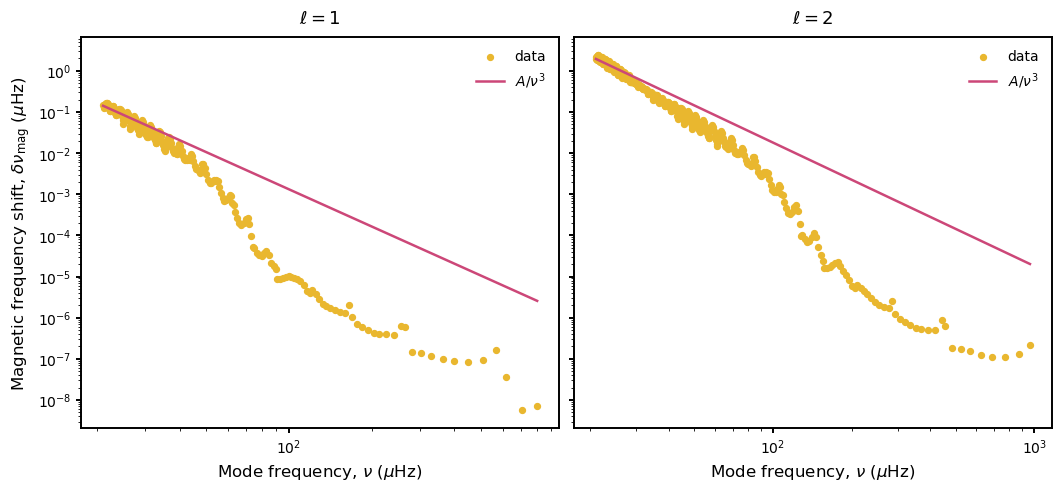

In [473]:
#fitting inverse cube trend for d10
d10_fit = clean_shift_data(d10)
d20_fit = clean_shift_data(d20)

def inv_cube(nu, A):#define the inverse-cube relation
    return A / nu**3

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), sharey=True, constrained_layout=True) 


for ell, data, ax in zip([1, 2], [d10_fit, d20_fit], axes):

    nu = data[:, 0] #frequencies
    shift = data[:, 1] #magnetic frequency shifts

    popt, _ = curve_fit(inv_cube, nu, shift) #best fitting 
    A = popt[0] #coefficient 
    trend = inv_cube(nu, A) #magnetic shifts

    print("Best-fit A for l =", ell, "m = 0:", A)

    # Plot 
    ax.scatter(nu, shift, s=18, color=m_colors[0], label="data", zorder=3)
    ax.plot(nu, trend, color=fit_color, linewidth=1.8, label=r"$A/\nu^3$", zorder=5)

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"Mode frequency, $\nu$ ($\mu$Hz)", fontsize=12)
    ax.set_title(r"$\ell=" + str(ell) + "$", fontsize=13, pad=10)
    ax.legend(frameon=False, fontsize=10)
    ax.tick_params(width=1.4, labelsize=10)

    for spine in ax.spines.values():
        spine.set_linewidth(1.4)

axes[0].set_ylabel(r"Magnetic frequency shift, $\delta\nu_{mag}$ ($\mu$Hz)", fontsize=12)

plt.show()


In [474]:
# Add magnetic frequency shifts to the rotationally split dipole modes
triplets_mag = triplets.copy() #copy of the rotational triplets
triplets_mag["delta_nu_mag"] = np.nan #empty column for the magnetic shifts

for m in [-1, 0, 1]: # go through the three rotational components
    data = mag_sequences[(1, m)] # magnetic shifts for thsi sequence
    magnetic_freq = data[:, 0] # frequencies from pymagn
    magnetic_shift = data[:, 1] #magnetic shifts from pymagn

    mask = triplets_mag["m"] == m #select the triplets with this m value

    for idx in triplets_mag[mask].index: # find the magnetic shift corresponding to each mode
        nu0 = float(np.real(triplets_mag.loc[idx, "nu0_muHz"])) #mode frequency
        closest = np.argmin(np.abs(magnetic_freq - nu0)) #find the closest frequency
        triplets_mag.loc[idx, "delta_nu_mag"] = magnetic_shift[closest] #assign its magnetic shift

print(triplets_mag[["n_g", "m", "nu0_muHz", "nu_split_muHz", "delta_nu_mag"]].head(9))


   n_g  m              nu0_muHz         nu_split_muHz  delta_nu_mag
0  204 -1  21.048652+ 0.000000j  20.952201+ 0.000000j      0.303204
1  204  0  21.048652+ 0.000000j  21.048652+ 0.000000j      0.149900
2  204  1  21.048652+ 0.000000j  21.145103+ 0.000000j      0.303204
3  203 -1  21.139583+ 0.000000j  21.043132+ 0.000000j      0.257803
4  203  0  21.139583+ 0.000000j  21.139583+ 0.000000j      0.127445
5  203  1  21.139583+ 0.000000j  21.236034+ 0.000000j      0.257803
6  202 -1  21.227972+ 0.000000j  21.131521+ 0.000000j      0.269839
7  202  0  21.227972+ 0.000000j  21.227972+ 0.000000j      0.133383
8  202  1  21.227972+ 0.000000j  21.324423+ 0.000000j      0.269839


In [475]:
# Check how close the matched frequencies are

triplets_mag["match_error_muHz"] = np.nan

for m in [-1, 0, 1]:
    data = mag_sequences[(1, m)] # get the magnetic data for this m
    magnetic_freq = data[:, 0] # get the frequencies

    modes = triplets_mag[triplets_mag["m"] == m] #select modes with this m

    for idx in modes.index:
        nu0 = float(np.real(triplets_mag.loc[idx, "nu0_muHz"])) #get the original frequency

        differences = abs(magnetic_freq - nu0) #find the difference from every magnetic frequency
        closest = np.argmin(differences) #find which frequency is closest
        error = differences[closest] # get the smallest difference

        triplets_mag.loc[idx, "match_error_muHz"] = error # save the error

print(triplets_mag["match_error_muHz"].describe())
print("Maximum matching error:", triplets_mag["match_error_muHz"].max(), "μHz")



count    6.060000e+02
mean     1.108914e+00
std      1.573456e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      3.552714e-15
max      2.240006e+02
Name: match_error_muHz, dtype: float64
Maximum matching error: 224.00064512894733 μHz


In [476]:
# Find modes with large frequency matching errors
limit = 1e-5 #maximum acceptable difference in μHz
bad_matches = triplets_mag[triplets_mag["match_error_muHz"] > limit] #keep modes with errors above the limit

print("Number of problematic matches:", len(bad_matches)) #Count them
columns = ["n_g", "m", "nu0_muHz", "match_error_muHz"]
print(bad_matches[columns].to_string(index=False)) 

Number of problematic matches: 3
 n_g  m                nu0_muHz  match_error_muHz
   3 -1 1025.100773+  0.000000j        224.000645
   3  0 1025.100773+  0.000000j        224.000645
   3  1 1025.100773+  0.000000j        224.000645


In [477]:
# Remove magnetic shifts that were matched to the wrong frequencies
limit = 1e-5 # maximum acceptable matching error in μHz
bad = triplets_mag["match_error_muHz"] > limit # find modes with errors above the limit
triplets_mag.loc[bad, "delta_nu_mag"] = np.nan # remove their magnetic shifts

valid = triplets_mag["delta_nu_mag"].notna().sum() 
missing = triplets_mag["delta_nu_mag"].isna().sum() 

print("Valid magnetic shifts:", valid)
print("Missing magnetic shifts:", missing)

Valid magnetic shifts: 603
Missing magnetic shifts: 3


In [478]:
#final dipole frequencies
triplets_mag["nu_final_muHz"] = np.real(triplets_mag["nu_split_muHz"]) + triplets_mag["delta_nu_mag"] #add the magnetic shifts to the rotationally split frequencies
triplets_mag["period_final_s"] = 1e6 / triplets_mag["nu_final_muHz"] # convert the final frequencies from μHz to periods in seconds

columns = ["n_g", "m", "nu0_muHz", "nu_split_muHz", "delta_nu_mag", "nu_final_muHz", "period_final_s"]

print(triplets_mag[columns].head(9)) 
valid = triplets_mag["nu_final_muHz"].notna().sum() #Count the frequencies that are not missing

print("\nValid final frequencies:", valid)

   n_g  m              nu0_muHz         nu_split_muHz  delta_nu_mag  \
0  204 -1  21.048652+ 0.000000j  20.952201+ 0.000000j      0.303204   
1  204  0  21.048652+ 0.000000j  21.048652+ 0.000000j      0.149900   
2  204  1  21.048652+ 0.000000j  21.145103+ 0.000000j      0.303204   
3  203 -1  21.139583+ 0.000000j  21.043132+ 0.000000j      0.257803   
4  203  0  21.139583+ 0.000000j  21.139583+ 0.000000j      0.127445   
5  203  1  21.139583+ 0.000000j  21.236034+ 0.000000j      0.257803   
6  202 -1  21.227972+ 0.000000j  21.131521+ 0.000000j      0.269839   
7  202  0  21.227972+ 0.000000j  21.227972+ 0.000000j      0.133383   
8  202  1  21.227972+ 0.000000j  21.324423+ 0.000000j      0.269839   

   nu_final_muHz  period_final_s  
0      21.255406    47046.855909  
1      21.198552    47173.032557  
2      21.448307    46623.727095  
3      21.300935    46946.295150  
4      21.267028    47021.144971  
5      21.493837    46524.965145  
6      21.401360    46726.001882  
7      21

In [479]:
# Match magnetic shifts to the quadrupole modes
quintuplets_mag = quintuplets.copy() # Make a copy of rotational multiplets

quintuplets_mag["delta_nu_mag"] = np.nan #column for the magnetic shifts
quintuplets_mag["match_error_muHz"] = np.nan # column for the matching errors

for m in [-2, -1, 0, 1, 2]: # go through the five rotational components
    data = mag_sequences[(2, m)] 
    magnetic_freq = data[:, 0] #frequencies
    magnetic_shift = data[:, 1] #magnetic shifts

    modes = quintuplets_mag[quintuplets_mag["m"] == m] # select modes with this m

    for idx in modes.index:
        nu0 = float(np.real(quintuplets_mag.loc[idx, "nu0_muHz"])) #original frequency

        differences = abs(magnetic_freq - nu0) #find the difference from every magnetic frequency
        closest = np.argmin(differences) #find which frequency is closest
        error = differences[closest] #get the smallest difference

        quintuplets_mag.loc[idx, "delta_nu_mag"] = magnetic_shift[closest]
        quintuplets_mag.loc[idx, "match_error_muHz"] = error 

print(quintuplets_mag["match_error_muHz"].describe())

limit = 1e-5 # max acceptable difference in microHz

bad = quintuplets_mag["match_error_muHz"] > limit # find modes with errors above the limit
bad_matches = quintuplets_mag[bad] # keep only those


columns = ["n_g", "m", "nu0_muHz", "match_error_muHz"]
print(bad_matches[columns].to_string(index=False)) # Show the problematic matches
quintuplets_mag.loc[bad, "delta_nu_mag"] = np.nan # replace these shifts with missing values
valid = quintuplets_mag["delta_nu_mag"].notna().sum() 
missing = quintuplets_mag["delta_nu_mag"].isna().sum() 

print("Valid magnetic shifts:", valid)
print("Missing magnetic shifts:", missing)

count    1.750000e+03
mean     2.352775e-01
std      4.396602e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      3.552714e-15
max      8.234712e+01
Name: match_error_muHz, dtype: float64

Modes with inaccurate matches:
 n_g  m              nu0_muHz  match_error_muHz
   6 -2 1045.36496+  0.00000j         82.347118
   6 -1 1045.36496+  0.00000j         82.347118
   6  0 1045.36496+  0.00000j         82.347118
   6  1 1045.36496+  0.00000j         82.347118
   6  2 1045.36496+  0.00000j         82.347118
Valid magnetic shifts: 1745
Missing magnetic shifts: 5


In [480]:
#final quadrupole frequencies including rotation and magnetism
quintuplets_mag["nu_final_muHz"] = np.real(quintuplets_mag["nu_split_muHz"]) + quintuplets_mag["delta_nu_mag"] # add the magnetic shifts to the rotationally split frequencies
quintuplets_mag["period_final_s"] = 1e6 / quintuplets_mag["nu_final_muHz"] # convert frequencies from μHz to periods in seconds

columns = ["n_g", "m", "nu0_muHz", "nu_split_muHz", "delta_nu_mag", "nu_final_muHz", "period_final_s"]

print(quintuplets_mag[columns].head(10))
valid = quintuplets_mag["nu_final_muHz"].notna().sum()

print("\nValid final frequencies:", valid)

   n_g  m              nu0_muHz         nu_split_muHz  delta_nu_mag  \
0  355 -2  21.000671+ 0.000000j  20.684313+ 0.000000j      1.178256   
1  355 -1  21.000671+ 0.000000j  20.842492+ 0.000000j      1.908622   
2  355  0  21.000671+ 0.000000j  21.000671+ 0.000000j      2.152091   
3  355  1  21.000671+ 0.000000j  21.158850+ 0.000000j      1.908622   
4  355  2  21.000671+ 0.000000j  21.317029+ 0.000000j      1.178256   
5  354 -2  21.058193+ 0.000000j  20.741835+ 0.000000j      1.077527   
6  354 -1  21.058193+ 0.000000j  20.900014+ 0.000000j      1.745576   
7  354  0  21.058193+ 0.000000j  21.058193+ 0.000000j      1.968271   
8  354  1  21.058193+ 0.000000j  21.216372+ 0.000000j      1.745576   
9  354  2  21.058193+ 0.000000j  21.374551+ 0.000000j      1.077527   

   nu_final_muHz  period_final_s  
0      21.862569    45740.278699  
1      22.751114    43953.891007  
2      23.152762    43191.390818  
3      23.067472    43351.086941  
4      22.495285    44453.759842  
5      2

In [481]:
#relative shifts

for label, df in [("Dipole", triplets_mag), ("Quadrupole", quintuplets_mag)]:

    magnetic_shift = abs(df["delta_nu_mag"]) # get the absolute magnetic shifts
    frequency = np.real(df["nu0_muHz"]) # get the original mode frequencies

    relative_shift = magnetic_shift / frequency # valculate the relative shift

    maximum = relative_shift.max() * 100
    median = relative_shift.median() * 100 
    above_10 = (relative_shift > 0.10).sum()

    print("\n", label, "modes:")
    print("Maximum relative shift:", round(maximum, 2), "%")
    print("Median relative shift:", round(median, 2), "%")
    print("Modes above 10%:", above_10)


Dipole modes:
Maximum relative shift: 1.57%
Median relative shift:  0.04%
Modes above 10%:        0

Quadrupole modes:
Maximum relative shift: 11.39%
Median relative shift:  0.24%
Modes above 10%:        11


In [ ]:
#period-spacing diagram for the final dipole spectrum

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

for m in [-1, 0, 1]:  # go through the three m components

    part = triplets_mag[  # keep only rows with this m and a valid final period
        (triplets_mag["m"] == m) &
        (triplets_mag["period_final_s"].notna())
    ].copy()

    P = np.array(part["period_final_s"], dtype=float)  # turn the periods into a NumPy array
    P = np.sort(P)  #sort from smallest to largest

    delta_P = np.diff(P)  
    P_mid = 0.5 * (P[1:] + P[:-1])  #midpoint period for each pair

    ax.plot(P_mid, delta_P, color=m_colors[m], marker="o", markersize=3.5, linewidth=1.2, label=fr"$m={m}$")

ax.set_xlabel("Mode period (s)", fontsize=12)
ax.set_ylabel(r"Period spacing, $\Delta P$ (s)", fontsize=12)
ax.set_title(r"Final dipole spectrum, $\ell=1$", fontsize=13, pad=10)
ax.legend(frameon=False, fontsize=10, ncol=3)
ax.tick_params(width=1.4, labelsize=10)

for spine in ax.spines.values():  #plot borders a bit thicker
    spine.set_linewidth(1.4)

plt.savefig("final_period_spacing_l1.png", dpi=300, bbox_inches="tight")  # save the figure
plt.show()

In [ ]:

# period-spacing diagram for the final quadrupole spectrum

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

for m in [-2, -1, 0, 1, 2]:  # go through the five m components

    part = quintuplets_mag[  #keep only rows with this m and a valid final period
        (quintuplets_mag["m"] == m) &
        (quintuplets_mag["period_final_s"].notna())
    ].copy()

    P = np.array(part["period_final_s"], dtype=float)  #turn the periods into a NumPy array
    P = np.sort(P)  # sort from smallest to largest

    delta_P = np.diff(P) 
    P_mid = 0.5 * (P[1:] + P[:-1])  # midpoint period for each pair

    ax.plot(P_mid, delta_P, color=m_colors[m], marker="o", markersize=3.5, linewidth=1.2, label=fr"$m={m}$")

ax.set_xlabel("Mode period (s)", fontsize=12)
ax.set_ylabel(r"Period spacing, $\Delta P$ (s)", fontsize=12)
ax.set_title(r"Final quadrupole spectrum, $\ell=2$", fontsize=13, pad=10)
ax.legend(frameon=False, fontsize=10, ncol=3)
ax.tick_params(width=1.4, labelsize=10)

for spine in ax.spines.values():  # borders a bit thicker
    spine.set_linewidth(1.4)

plt.savefig("final_period_spacing_l2.png", dpi=300, bbox_inches="tight")  #save the figure
plt.show()

In [ ]:
# Compared to the original non-rotating, non-magnetic spectrum and plot cahnges
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True, constrained_layout=True)

for ax, ell, df in [(axes[0], 1, triplets_mag), (axes[1], 2, quintuplets_mag)]: 

    for m in range(-ell, ell + 1):  # go through all m components

        part = df[  # keep modes with this m and a valid final period
            (df["m"] == m) &
            (df["period_final_s"].notna())
        ].copy()

        part = part.sort_values("n_g")  # sort modes by radial order

        n = part["n_g"].to_numpy()  
        P_final = part["period_final_s"].to_numpy(dtype=float) 
        P0 = 1e6 / np.real(part["nu0_muHz"].to_numpy())  #GYRE periods in seconds

        consecutive = np.abs(np.diff(n)) == 1  # find the pairs with consecutive radial orders

        deltaP_final = np.diff(P_final)  
        deltaP_0 = np.diff(P0)  #original period spacings

        spacing_difference = deltaP_final - deltaP_0  #diffrence in period spacing

        P_mid = 0.5 * (P0[1:] + P0[:-1]) 

        P_mid = P_mid[consecutive]  #remove any pairs with missing radial orders
        spacing_difference = spacing_difference[consecutive]  #and keep only the corresponding spacing changes

        ax.plot(P_mid, spacing_difference, color=m_colors[m], marker="o", markersize=3, linewidth=1.2, label=fr"$m={m}$")

    ax.axhline(0, color="black", linestyle="--", linewidth=1.4)  # line at zero
    ax.set_title(fr"$\ell={ell}$", fontsize=13, pad=8)
    ax.set_ylabel(r"$\Delta P_{\mathrm{final}}-\Delta P_0$ (s)", fontsize=17)
    ax.legend(frameon=False, ncol=3, fontsize=14)
    ax.tick_params(width=1.4, labelsize=14)

    for spine in ax.spines.values():  #borders thicker
        spine.set_linewidth(1.4)

axes[1].set_xlabel(r"Unperturbed mode period $P_0$ (s)", fontsize=17)

plt.savefig("final_period_spacing_differences.png", dpi=300, bbox_inches="tight")  #save the figure
plt.show()

In [ ]:
# Echelle diagram for the final dipole modes with rotation + magnetism
DeltaPi = mean_Delta_P1  #in seconds
shift = 67.5

plt.figure(figsize=(8, 9.5))

colors = {-1: m_colors[-1], 0: m_colors[0], 1: m_colors[1]}  # colors each m component

for m in [-1, 0, 1]:  #go through the m components

    mask = (triplets_mag["m"] == m) & (triplets_mag["period_final_s"].notna())  # valid modes

    P_data = np.array(triplets_mag.loc[mask, "period_final_s"], dtype=float)  
    x_data = np.mod(P_data + shift, DeltaPi) 

    c = colors[m]  #color for this m component

    plt.scatter(x_data, P_data, color=c, s=8)  # plot the actual modes
    plt.scatter(x_data - DeltaPi, P_data, color=c, s=8, alpha=0.4)  # left copy
    plt.scatter(x_data + DeltaPi, P_data, color=c, s=8, alpha=0.4)  # Right copy

    idx = np.argsort(P_data)  #periods from smallest to largest
    P_sorted = P_data[idx] 
    x_raw = x_data[idx]

    x_connect = np.zeros_like(x_raw)  #create an array for the connected x positions
    x_connect[0] = x_raw[0]  

    connect_Pmin = 10000  #period above which the connection can switch copies

    for i in range(1, len(x_raw)):  #go through the remaining modes

        if P_sorted[i] < connect_Pmin:
            x_connect[i] = x_raw[i]  # At low periods, stay in the original copy

        else:
            options = np.array([x_raw[i] - DeltaPi, x_raw[i], x_raw[i] + DeltaPi])  #from the three possible positions
            x_connect[i] = options[np.argmin(np.abs(options - x_connect[i-1]))]  # choose the closest to the previous point

    plt.plot(x_connect, P_sorted, color=c, alpha=0.85, lw=1.3, label=fr"$m={m}$")  
    plt.plot(x_connect - DeltaPi, P_sorted, color=c, alpha=0.2, lw=1)  
    plt.plot(x_connect + DeltaPi, P_sorted, color=c, alpha=0.2, lw=1)  

plt.xlabel(r"P mod $\Delta\Pi_1$ (s)")
plt.ylabel("Mode period (s)")
plt.title(r"Magnetized and Rotationally Split $\ell=1$ Period Échelle Diagram")
plt.xlim(-DeltaPi/2, 1.5*DeltaPi)

ax = plt.gca()

for spine in ax.spines.values(): 
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

ax.tick_params(axis="both", width=1.3, length=4)

plt.legend(loc="lower left", frameon=True, facecolor="white", edgecolor="black", framealpha=1.0)

plt.savefig("echelle_final_l1.png", dpi=300, bbox_inches="tight") 
plt.show()

In [ ]:
# Rescale magnetic field strength and plot the final dipole echelle diagram

def plot_magnetic_echelle(factor=1.0):
    DeltaPi = mean_Delta_P1
    shift = 67.5
    connect_Pmin = 10000

    df = triplets_mag.copy()  # make a copy 

    df["delta_nu_scaled"] = df["delta_nu_mag"] * factor**2  # shifts scale with B squared

    df["nu_scaled_muHz"] = np.real(df["nu_split_muHz"]) + df["delta_nu_scaled"]  # Add rotationally split frequencies

    df["period_scaled_s"] = 1e6 / df["nu_scaled_muHz"]  #periods in seconds

    fig, ax = plt.subplots(figsize=(8, 9.5))

    for m in [-1, 0, 1]:  #go through the three m components

        part = df[  (df["m"] == m) & (df["period_scaled_s"].notna())].copy()
        part = part.sort_values("period_scaled_s")  # sort modes by period

        P_data = part["period_scaled_s"].to_numpy(dtype=float)
        x_data = np.mod(P_data + shift, DeltaPi) 
        c = m_colors[m]

        ax.scatter(x_data, P_data, color=c, s=8, alpha=1.0)  #actual modes
        ax.scatter(x_data - DeltaPi, P_data, color=c, s=8, alpha=0.4)  # Left copy
        ax.scatter(x_data + DeltaPi, P_data, color=c, s=8, alpha=0.4)  # Right copy

        x_connect = np.zeros_like(x_data) 
        x_connect[0] = x_data[0] 

        for i in range(1, len(x_data)):  # go through the remaining modes

            if P_data[i] < connect_Pmin:
                x_connect[i] = x_data[i]  # at low periods, use the original position

            else:
                options = np.array([x_data[i] - DeltaPi, x_data[i], x_data[i] + DeltaPi])  # of the possible positions
                x_connect[i] = options[np.argmin(np.abs(options - x_connect[i-1]))]  # choose the closest

        ax.plot(x_connect, P_data, color=c, lw=1.3, alpha=0.85, label=fr"$m={m}$") 
        ax.plot(x_connect - DeltaPi, P_data, color=c, lw=1, alpha=0.2) 
        ax.plot(x_connect + DeltaPi, P_data, color=c, lw=1, alpha=0.2) 
    ax.set_xlabel(r"P mod $\Delta\Pi_1$ (s)")
    ax.set_ylabel("Mode period (s)")
    ax.set_title(fr"$\ell=1$ — Magnetic field factor $f={factor:g}$")
    ax.set_xlim(-DeltaPi/2, 1.5*DeltaPi)

    for spine in ax.spines.values():  #make borders thicker
        spine.set_visible(True)
        spine.set_linewidth(1.5)
        spine.set_color("black")

    ax.tick_params(axis="both", width=1.3, length=4)
    ax.legend(loc="lower left", frameon=True, facecolor="white", edgecolor="black", framealpha=1.0)

    plt.show()

    return df


# plot with the magnetic field multiplied by 5
df_reference = plot_magnetic_echelle(factor=5.0)


In [ ]:
B0 = 1000  # G
nu_det = 0.00795  # μHz

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, constrained_layout=True)
for ax, ell in zip(axes, [1, 2]):  

    for m in range(ell + 1):  # go through the each m value
        data = mag_sequences[(ell, m)]
        nu = data[:, 0]  # μHz
        dnu_mag = np.abs(data[:, 1])  # Absolute magnetic frequency shifts

        B_det = B0 * np.sqrt(nu_det / dnu_mag)  #minimum detectable magnetic field
        P_days = 1e6 / (nu * 86400)  #period in days

        s = np.argsort(P_days)  #sort by period
        P_days = P_days[s]
        B_det = B_det[s]

        ax.scatter(P_days, B_det, s=15, color=m_colors[m], label=fr"$m={m}$")

    ax.set_yscale("log")
    ax.set_xlabel(r"Mode period, $P$ (days)")
    ax.set_title(fr"$\ell={ell}$")
    ax.legend(frameon=False)

axes[0].set_ylabel(r"Minimum detectable field, $B_{\rm det}$ (G)")

plt.savefig("magnetic_detectability_period.png", dpi=300, bbox_inches="tight")  # Save
plt.show()